# DengAI — Exploratory Data Analysis

**Goal.** Understand the DengAI data well enough to make sound modelling choices for predicting weekly dengue cases (`total_cases`) in two cities — **San Juan (`sj`)** and **Iquitos (`iq`)** — several years beyond the training period.

**Notebook map**

| Part | Section | Question |
|---|---|---|
| A | 1–3 | Are the files consistent, and how do train and test relate in time? |
| A | 4–5 | What is missing, what is redundant, and which units need aligning? |
| A | 6–8 | What does the target look like, and how does it vary over time and across the year? |
| A | 9–12 | How do the environmental variables differ by city, relate to cases, and behave over time and at lags? |
| B | 13–15 | Gaps in the first pass: overdispersion, year-to-year level shifts, cross-city differences |
| B | 16 | Summary of findings and modelling implications |

**Conventions**
- Missing values stay missing during EDA (a missing value is not zero). Any imputation belongs inside the training folds of a model.
- Statistics are computed **within each city** unless stated; the two cities seems to differ.
- Only training labels are used for target statistics. The test period has no labels.
- Correlations here are descriptive: the series are autocorrelated and seasonal, so p-values are unreliable and nothing here is causal.

**Feature groups** (per the competition description)

| Group | Columns | Source |
|---|---|---|
| Vegetation | `ndvi_ne`, `ndvi_nw`, `ndvi_se`, `ndvi_sw` | Satellite NDVI for the pixel NE/NW/SE/SW of the city centroid |
| Satellite precipitation | `precipitation_amt_mm` | Satellite rainfall estimate |
| Reanalysis (NCEP) | `reanalysis_*` — air/avg/min/max/dew-point temperature (K), relative & specific humidity, precipitation (kg/m²), diurnal range (`tdtr`) | Gridded climate reanalysis |
| Weather station | `station_*` — avg/min/max temperature, diurnal range (°C), precipitation (mm) | Single ground station per city |
| Keys / time | `city`, `year`, `weekofyear`, `week_start_date` | — |
| Target (train only) | `total_cases` | Weekly dengue cases |

# Part A — First-pass EDA

## 1. Setup and data loading

In [1]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

pd.set_option('display.max_columns', 40)

# Shared constants
FOLDER = Path('../data/raw')
if not FOLDER.is_dir() and Path('data/raw').is_dir():
    FOLDER = Path('data/raw')
KEYS = ['city', 'year', 'weekofyear']
TARGET = 'total_cases'
CITIES = ['sj', 'iq']
CITY_NAMES = {'sj': 'San Juan', 'iq': 'Iquitos'}
COLORS = {'sj': '#2563eb', 'iq': '#d97706'}

df_train_feature = pd.read_csv(FOLDER / 'dengue_features_train.csv', parse_dates=['week_start_date'])
df_train_label = pd.read_csv(FOLDER / 'dengue_labels_train.csv')
df_test_feature = pd.read_csv(FOLDER / 'dengue_features_test.csv', parse_dates=['week_start_date'])
df_submission = pd.read_csv(FOLDER / 'submission_format.csv')

datasets = {
    'train_features': df_train_feature,
    'train_labels': df_train_label,
    'test_features': df_test_feature,
    'submission_format': df_submission,
}
display(pd.DataFrame({name: {'rows': len(df), 'columns': df.shape[1]} for name, df in datasets.items()}).T)

,rows,columns
train_features,1456,24
train_labels,1456,4
test_features,416,24
submission_format,416,4


## 2. Data integrity

Checks, in order: (1) `year`/`weekofyear` agree with `week_start_date`; (2) keys are complete and unique in every file; (3) features and labels join one-to-one; (4) train and test keys do not overlap and the test keys match the submission template; (5) targets are non-negative integers.

The submission file's `total_cases` column is only a placeholder of zeros and is never used as data.

In [2]:
# (1) Calendar consistency: year and ISO week should follow from week_start_date
results = []
for name, df in [('train', df_train_feature), ('test', df_test_feature)]:
    dates = pd.to_datetime(df['week_start_date'], format='%Y-%m-%d', errors='coerce')
    year_ok = df['year'].eq(dates.dt.year).fillna(False)
    week_ok = df['weekofyear'].eq(dates.dt.isocalendar().week).fillna(False)
    consistent = dates.notna() & year_ok & week_ok
    results.append({'dataset': name, 'rows': len(df), 'invalid_dates': dates.isna().sum(),
                    'year_mismatches': (~year_ok).sum(), 'week_mismatches': (~week_ok).sum(),
                    'inconsistent_rows': (~consistent).sum()})
    if not consistent.all():
        display(df.loc[~consistent, KEYS + ['week_start_date']])
date_summary = pd.DataFrame(results).set_index('dataset')
display(date_summary)
assert date_summary['inconsistent_rows'].eq(0).all(), 'Date inconsistencies found.'

,rows,invalid_dates,year_mismatches,week_mismatches,inconsistent_rows
dataset,,,,,
train,1456,0,0,0,0
test,416,0,0,0,0


In [3]:
# (2)-(5) Keys, joins and target validity

key_audit = pd.DataFrame({
    name: {'rows': len(df),
           'rows_with_missing_keys': int(df[KEYS].isna().any(axis=1).sum()),
           'duplicate_key_rows_after_first': int(df.duplicated(KEYS).sum())}
    for name, df in datasets.items()
}).T
display(key_audit)
assert key_audit['rows_with_missing_keys'].eq(0).all(), 'Missing join keys found.'
assert key_audit['duplicate_key_rows_after_first'].eq(0).all(), 'Duplicate join keys found.'
assert df_train_feature.columns.tolist() == df_test_feature.columns.tolist(), 'Feature schemas differ.'

df_train = df_train_feature.merge(df_train_label, on=KEYS, how='outer', validate='one_to_one', indicator=True)
print('Training feature-label matches:')
display(df_train['_merge'].value_counts())
assert df_train['_merge'].eq('both').all(), 'Features and labels have unmatched keys.'
df_train = df_train.drop(columns='_merge').sort_values(['city', 'week_start_date']).reset_index(drop=True)
df_test = df_test_feature.sort_values(['city', 'week_start_date']).reset_index(drop=True)

submission_check = df_test_feature[KEYS].merge(df_submission[KEYS], on=KEYS, how='outer',
                                               validate='one_to_one', indicator=True)
assert submission_check['_merge'].eq('both').all(), 'Test and submission keys differ.'
assert df_train_feature[KEYS].merge(df_test_feature[KEYS], on=KEYS).empty, 'Train/test keys overlap.'
assert df_train[TARGET].notna().all(), 'Missing training labels.'
assert df_train[TARGET].ge(0).all(), 'Negative case counts.'
assert df_train[TARGET].mod(1).eq(0).all(), 'Case counts must be integers.'
print('All key and target checks passed. Training table:', df_train.shape)

,rows,rows_with_missing_keys,duplicate_key_rows_after_first
train_features,1456,0,0
train_labels,1456,0,0
test_features,416,0,0
submission_format,416,0,0


Training feature-label matches:


_merge
both          1456
left_only        0
right_only       0
Name: count, dtype: int64

All key and target checks passed. Training table: (1456, 25)


## 3. Time coverage and the train/test boundary

The test set is a **forecast**, not a random hold-out: for each city the test weeks come strictly after the training weeks, and the test period is long (about 5 years for `sj`, 3 years for `iq`). Dates are nominally weekly but sometimes advance by 8 or 9 days; these are reported rather than "fixed". A gap in days does not by itself mean a row is missing.

In [4]:
coverage = pd.concat([
    df.groupby('city').agg(rows=('city', 'size'), first_date=('week_start_date', 'min'),
                           last_date=('week_start_date', 'max')).assign(split=split)
    for split, df in [('train', df_train), ('test', df_test)]
]).reset_index()
display(coverage[['city', 'split', 'rows', 'first_date', 'last_date']])

interval_tables = []
for split, df in [('train', df_train), ('test', df_test)]:
    assert not df.duplicated(['city', 'week_start_date']).any(), 'Repeated dates within a city.'
    for city, group in df.groupby('city'):
        gaps = group.sort_values('week_start_date')['week_start_date'].diff().dt.days.dropna()
        interval_tables.append(gaps.value_counts().rename_axis('days_between_records')
                                   .reset_index(name='interval_count').assign(city=city, split=split))
display(pd.concat(interval_tables, ignore_index=True).sort_values(['city', 'split', 'days_between_records']))

for city in CITIES:
    train_last = df_train.loc[df_train['city'].eq(city), 'week_start_date'].max()
    test_first = df_test.loc[df_test['city'].eq(city), 'week_start_date'].min()
    assert train_last < test_first, f'Test does not follow training for {city}.'

,city,split,rows,first_date,last_date
0,iq,train,520,2000-07-01,2010-06-25
1,sj,train,936,1990-04-30,2008-04-22
2,iq,test,156,2010-07-02,2013-06-25
3,sj,test,260,2008-04-29,2013-04-23


,days_between_records,interval_count,city,split
6,7.0,152,iq,test
7,8.0,2,iq,test
8,9.0,1,iq,test
0,7.0,509,iq,train
1,8.0,7,iq,train
2,9.0,3,iq,train
9,7.0,254,sj,test
10,8.0,3,sj,test
11,9.0,2,sj,test
3,7.0,917,sj,train


## 4. Missing values

Reported by city and split, then in time order. We look for (a) which features are affected, (b) whether missingness differs between train and test, and (c) whether it is scattered or in long blocks.

,dtype,n_missing,pct_missing,n_unique,examples
city,str,0,0.00,2,"[iq, sj]"
year,int64,0,0.00,21,"[2000, 2001, 2002]"
weekofyear,int64,0,0.00,53,"[26, 27, 28]"
week_start_date,datetime64[us],0,0.00,1049,"[2000-07-01 00:00:00, 2000-07-08 00:00:00, 200..."
ndvi_ne,float64,194,13.32,1214,"[0.192886, 0.216833, 0.176757]"
ndvi_nw,float64,52,3.57,1365,"[0.132257, 0.2761, 0.173129]"
ndvi_se,float64,22,1.51,1395,"[0.340886, 0.289457, 0.204114]"
ndvi_sw,float64,22,1.51,1388,"[0.2472, 0.241657, 0.128014]"
precipitation_amt_mm,float64,13,0.89,1157,"[25.41, 60.61, 55.52]"
reanalysis_air_temp_k,float64,10,0.69,1176,"[296.74, 296.634286, 296.415714]"


,train / sj,train / iq,test / sj,test / iq
ndvi_ne,20.41,0.58,16.54,0.00
station_diur_temp_rng_c,0.64,7.12,0.77,6.41
station_avg_temp_c,0.64,7.12,0.77,6.41
ndvi_nw,5.24,0.58,4.23,0.00
station_min_temp_c,0.64,1.54,0.77,4.49
station_precip_mm,0.64,3.08,0.77,1.92
station_max_temp_c,0.64,2.69,0.77,0.64
ndvi_se,2.03,0.58,0.38,0.00
ndvi_sw,2.03,0.58,0.38,0.00
precipitation_amt_mm,0.96,0.77,0.77,0.00


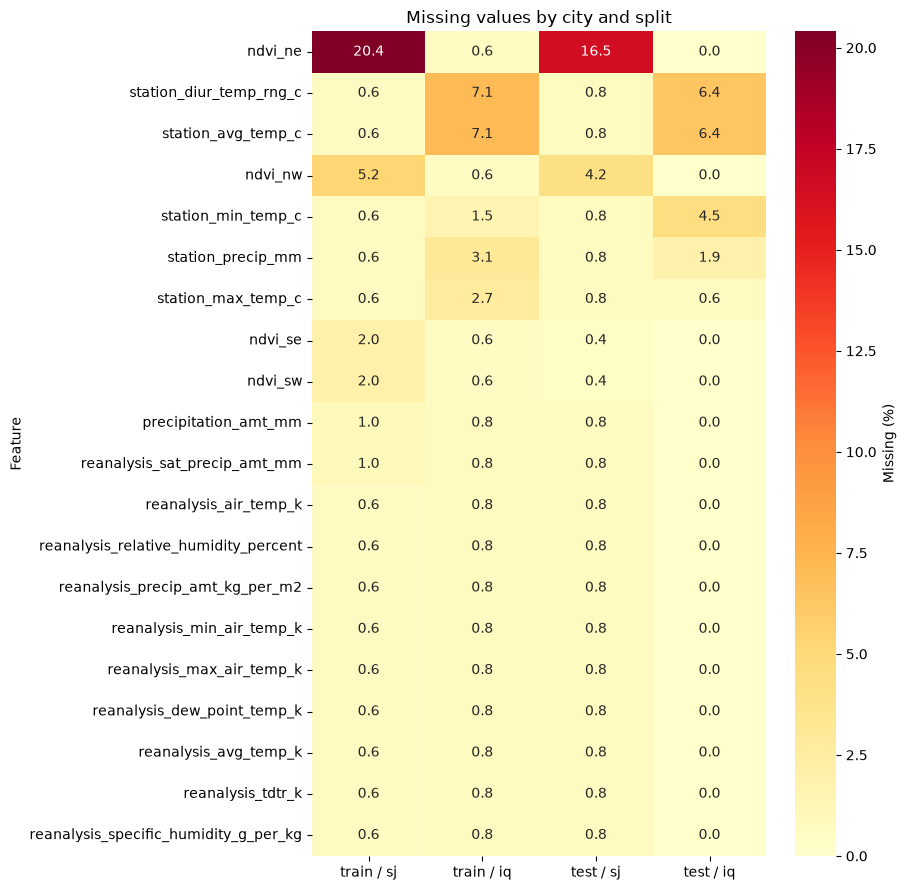

In [5]:
raw_feature_cols = [c for c in df_train_feature.columns if c not in KEYS + ['week_start_date']]

def profile(df):
    return pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'n_missing': df.isna().sum(),
        'pct_missing': df.isna().mean().mul(100).round(2),
        'n_unique': df.nunique(),
        'examples': [df[c].dropna().unique()[:3].tolist() for c in df.columns],
    })
display(profile(df_train))

missing_pct = pd.DataFrame({
    f'{split} / {city}': df.loc[df['city'].eq(city), raw_feature_cols].isna().mean().mul(100)
    for split, df in [('train', df_train), ('test', df_test)]
    for city in CITIES
})
missing_pct = missing_pct.loc[missing_pct.max(axis=1).sort_values(ascending=False).index]
display(missing_pct.round(2))

fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(missing_pct, annot=True, fmt='.1f', cmap='YlOrRd', vmin=0,
            cbar_kws={'label': 'Missing (%)'}, ax=ax)
ax.set_title('Missing values by city and split')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

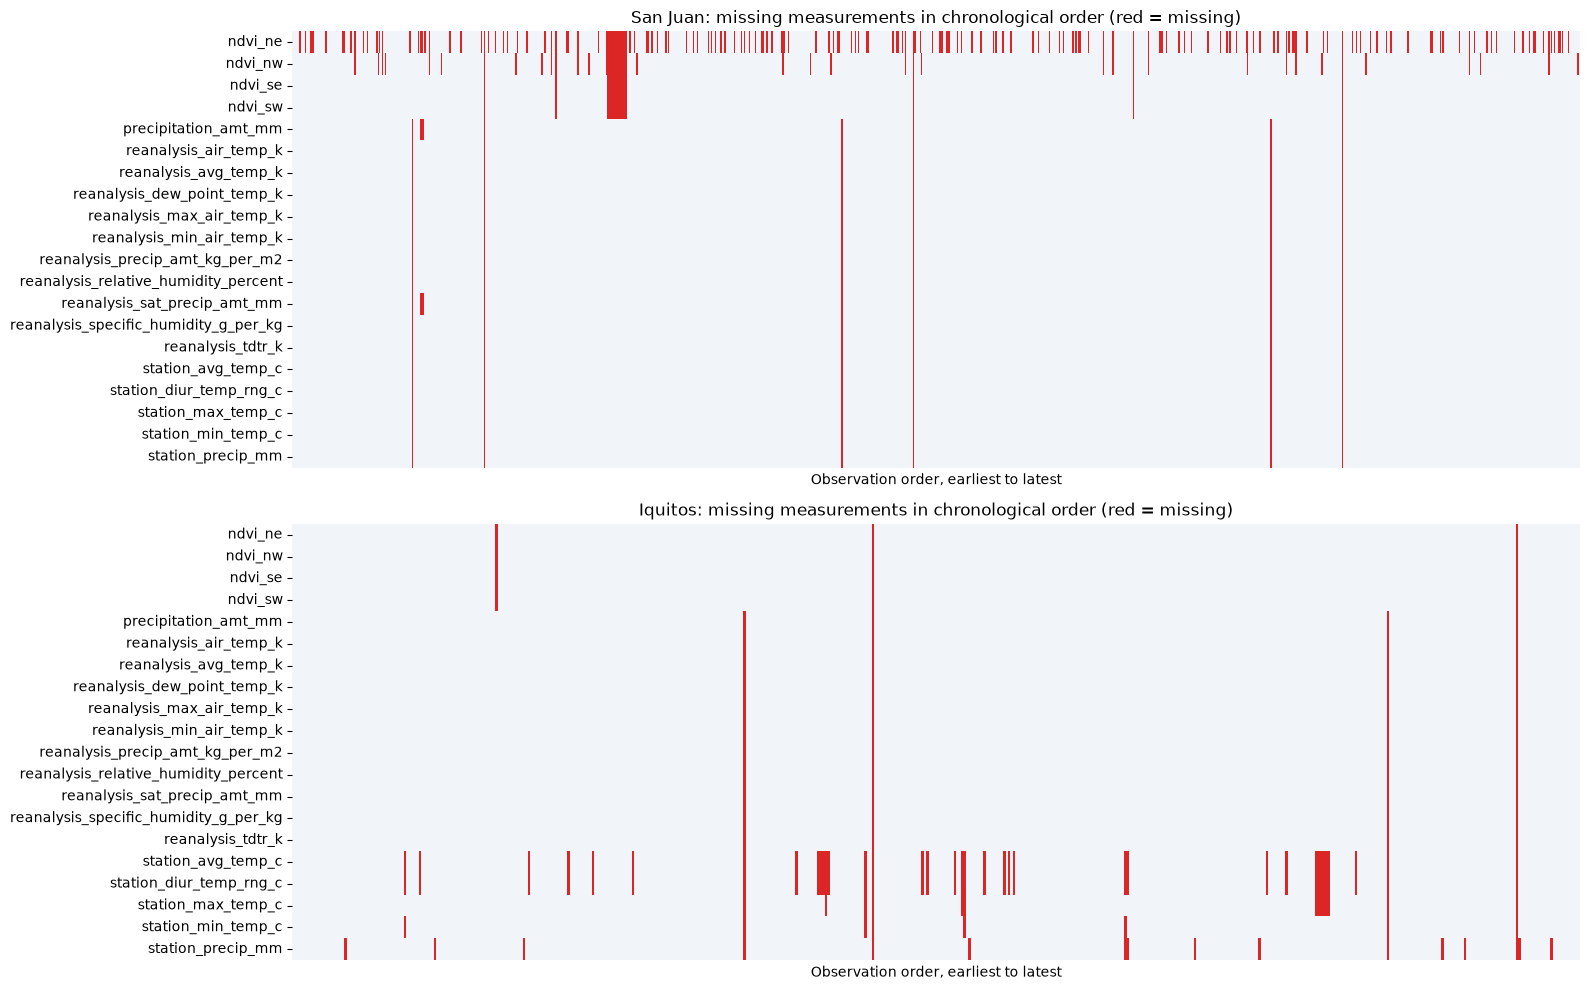

In [6]:
# Missing measurements in chronological order (red = missing)
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
for ax, city in zip(axes, CITIES):
    group = df_train.loc[df_train['city'].eq(city)].sort_values('week_start_date')
    sns.heatmap(group[raw_feature_cols].isna().T.astype(int), cmap=['#f1f5f9', '#dc2626'],
                vmin=0, vmax=1, cbar=False, xticklabels=False, yticklabels=True, ax=ax)
    ax.set_title(f'{CITY_NAMES[city]}: missing measurements in chronological order (red = missing)')
    ax.set_xlabel('Observation order, earliest to latest')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Observations (§4).** Missingness is concentrated in a few features. `ndvi_ne` is missing for about 20% of `sj` training weeks and 17% of `sj` test weeks (almost none for `iq`). `iq` station temperature is missing for about 7% of training weeks and 6% of test weeks. The reanalysis variables are almost complete (under 1%). The chronological plot shows scattered short gaps rather than one long block.

## 5. Units and redundancy

- Kelvin temperatures are converted to Celsius on **EDA copies** (`df_train_eda`, `df_test_eda`); the original tables stay untouched. A temperature *range* has the same numeric value in K and °C, so `tdtr` is only renamed.
- Exact duplicate columns are detected (equal values and equal missing positions in both train and test) and dropped from repeated charts only.

In [7]:
absolute_temp_k = ['reanalysis_air_temp_k', 'reanalysis_avg_temp_k', 'reanalysis_dew_point_temp_k',
                   'reanalysis_max_air_temp_k', 'reanalysis_min_air_temp_k']

def temperatures_to_celsius(df):
    result = df.copy()
    result[absolute_temp_k] = result[absolute_temp_k] - 273.15
    result = result.rename(columns={c: c[:-2] + '_c' for c in absolute_temp_k})
    return result.rename(columns={'reanalysis_tdtr_k': 'reanalysis_tdtr_c'})

df_train_eda = temperatures_to_celsius(df_train)
df_test_eda = temperatures_to_celsius(df_test)
feature_cols = [c for c in df_train_eda.columns if c not in KEYS + ['week_start_date', TARGET]]

duplicate_pairs = [(a, b) for a, b in combinations(feature_cols, 2)
                   if df_train_eda[a].equals(df_train_eda[b]) and df_test_eda[a].equals(df_test_eda[b])]
display(pd.DataFrame(duplicate_pairs, columns=['column_1', 'column_2']))

redundant_for_plots = {b for _, b in duplicate_pairs}   # {'reanalysis_sat_precip_amt_mm'}
plot_features = [c for c in feature_cols if c not in redundant_for_plots]
print(f'{len(feature_cols)} environmental columns, {len(plot_features)} used in plots')
display(df_train_eda.groupby('city')[feature_cols].describe().round(2).T)

,column_1,column_2
0,precipitation_amt_mm,reanalysis_sat_precip_amt_mm


20 environmental columns, 19 used in plots


city                         iq      sj
ndvi_ne           count  517.00  745.00
                  mean     0.26    0.06
                  std      0.08    0.11
                  min      0.06   -0.41
                  25%      0.20    0.00
...                         ...     ...
station_precip_mm min      0.00    0.00
                  25%     17.20    6.82
                  50%     45.30   17.75
                  75%     85.95   35.45
                  max    543.30  305.90

[160 rows x 2 columns]

**Observations (§5).** One exact duplicate pair exists (`precipitation_amt_mm` = `reanalysis_sat_precip_amt_mm`).

## 6. Target distribution

Case counts are compared by city on the raw scale and on `log1p` (a *plotting* transform that makes the low-count region and the long tail visible; it does not commit a model to a transformed target). Zero rainfall and zero cases are valid values.

,n_weeks,mean,median,std,minimum,maximum,zero_case_weeks,pct_zero
city,,,,,,,,
iq,520,7.57,5.0,10.77,0,116,96,18.46
sj,936,34.18,19.0,51.38,0,461,4,0.43


,0.50,0.90,0.95,0.99
city,,,,
iq,5.0,19.1,28.0,44.81
sj,19.0,71.0,112.0,319.55


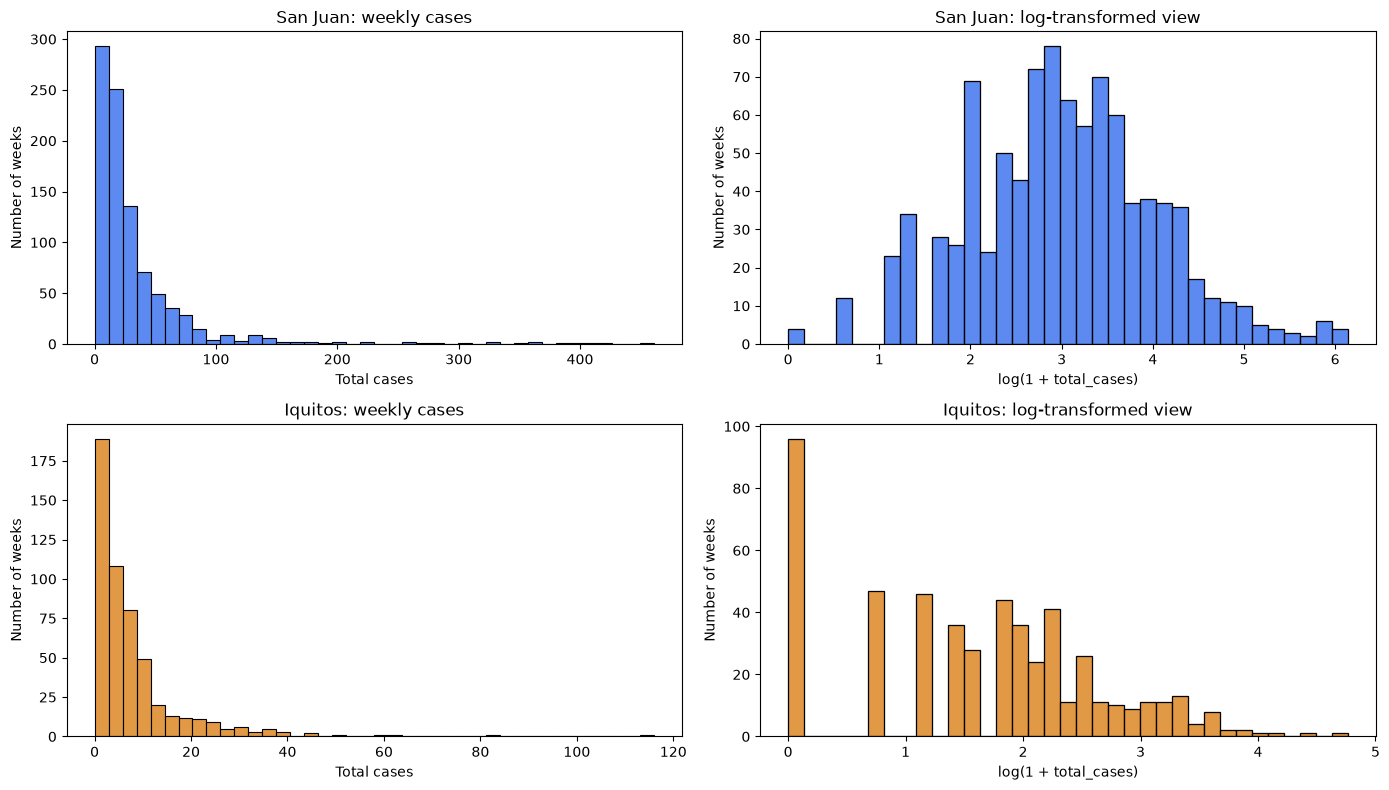

,sj,iq
total_cases,,
0,4,96
1,12,47
2,23,46
3,34,36
4,28,28
5,26,44
6,35,36
7,34,24
8,24,20


In [8]:
target_summary = df_train.groupby('city')[TARGET].agg(
    n_weeks='size', mean='mean', median='median', std='std', minimum='min', maximum='max',
    zero_case_weeks=lambda s: s.eq(0).sum(), pct_zero=lambda s: s.eq(0).mean() * 100)
display(target_summary.round(2))
display(df_train.groupby('city')[TARGET].quantile([0.5, 0.9, 0.95, 0.99]).unstack().round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, city in enumerate(CITIES):
    values = df_train.loc[df_train['city'].eq(city), TARGET]
    sns.histplot(x=values, bins=40, color=COLORS[city], ax=axes[row, 0])
    axes[row, 0].set(title=f'{CITY_NAMES[city]}: weekly cases', xlabel='Total cases', ylabel='Number of weeks')
    sns.histplot(x=np.log1p(values), bins=35, color=COLORS[city], ax=axes[row, 1])
    axes[row, 1].set(title=f'{CITY_NAMES[city]}: log-transformed view', xlabel='log(1 + total_cases)', ylabel='Number of weeks')
plt.tight_layout()
plt.show()

case_frequencies = {city: df_train.loc[df_train['city'].eq(city), TARGET].value_counts().sort_index() for city in CITIES}
display(pd.DataFrame(case_frequencies).fillna(0).astype(int).rename_axis(TARGET).head(15))

**Observations (§6).** The two cities are on different scales. `sj`: mean 34.2, median 19, maximum 461, almost never zero (0.4% of weeks). `iq`: mean 7.6, median 5, maximum 116, and 18.5% of weeks are zero. Both are right-skewed with heavy tails (the 99th percentile is about 17× the median for `sj` and 9× for `iq`). Variance is far above the mean (quantified in §13).

## 7. Cases and weather over time

Looks for outbreaks, shifting baselines and recurring peaks, and puts the weather trend on the same plot so timing can be compared by eye. Cases are on the left axis (city colour: faint line = weekly value, thick line = trailing 8-observation mean). Weather is on the right axis and is also a trailing 8-observation mean, so seasonal swings are readable (visual aid only; missing values are left as gaps, not filled). Each city has its own panels and axes. Grey shading marks the test period, where labels are unknown. Weather columns come from the cleaned EDA copy `df_train_eda` (temperatures in °C).

Four plots: (1) reanalysis temperature features, (2) station temperature features, (3) precipitation (`reanalysis_sat_precip_amt_mm` and `station_precip_mm`), (4) humidity features. `reanalysis_sat_precip_amt_mm` is identical to `precipitation_amt_mm` (§5), so one line stands for both. The two humidity features have different units (% and g/kg), so each gets its own right-hand axis. These are descriptive views of timing, not evidence of a causal relationship. The largest counts are listed below, **not removed**: they are real outbreaks.

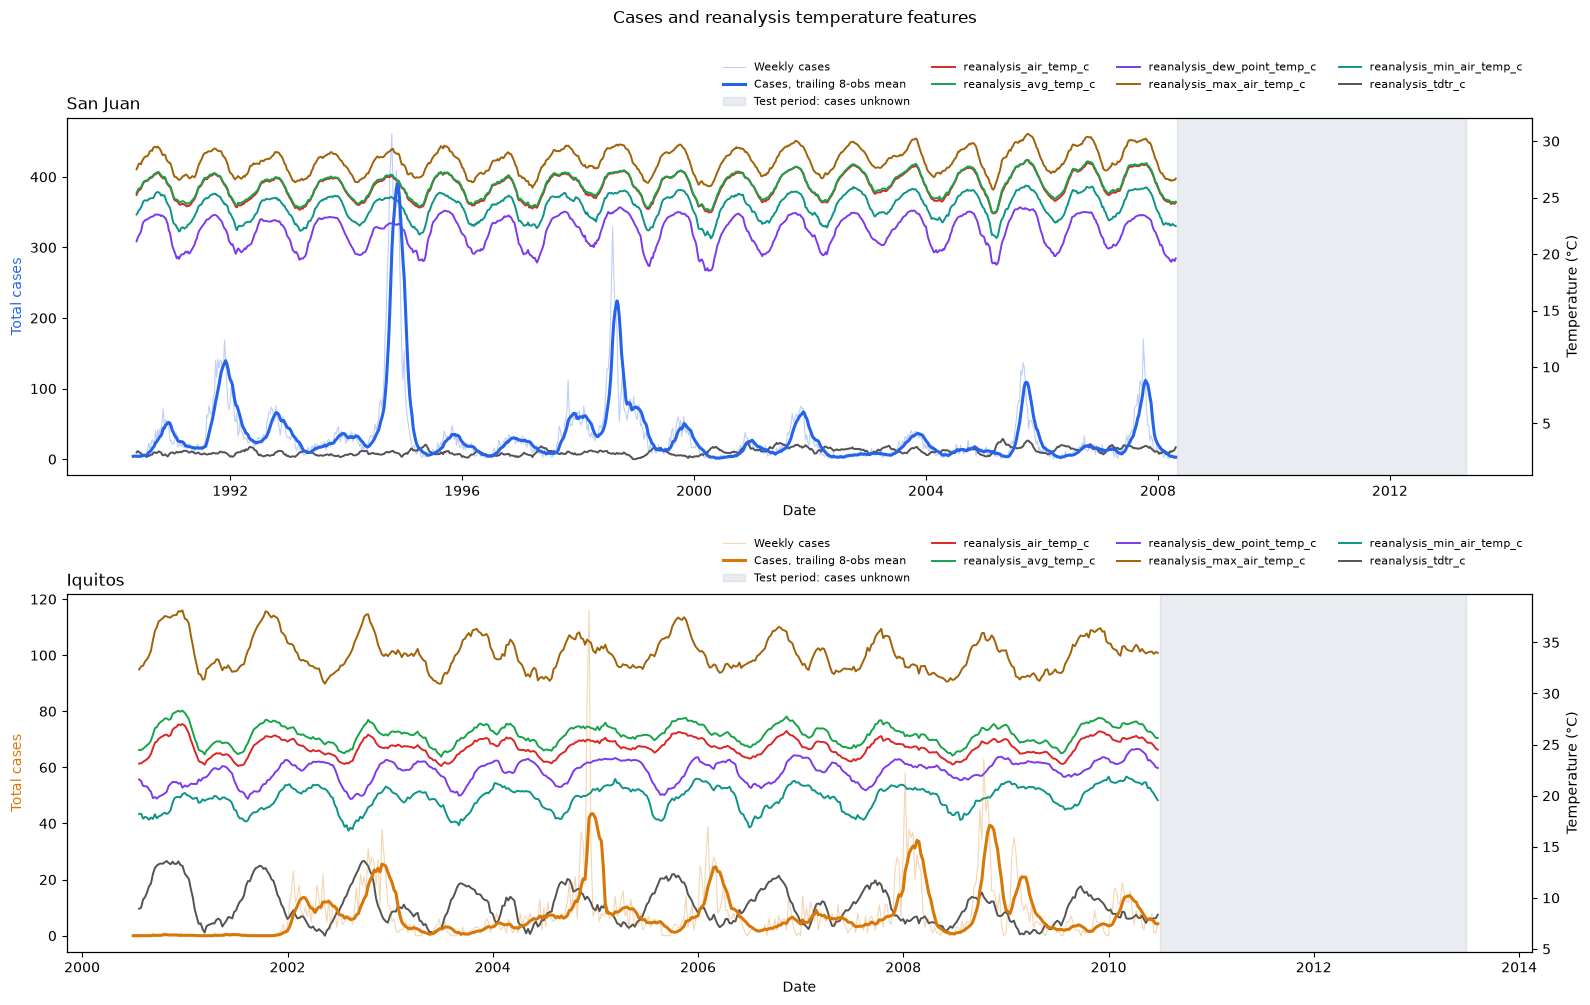

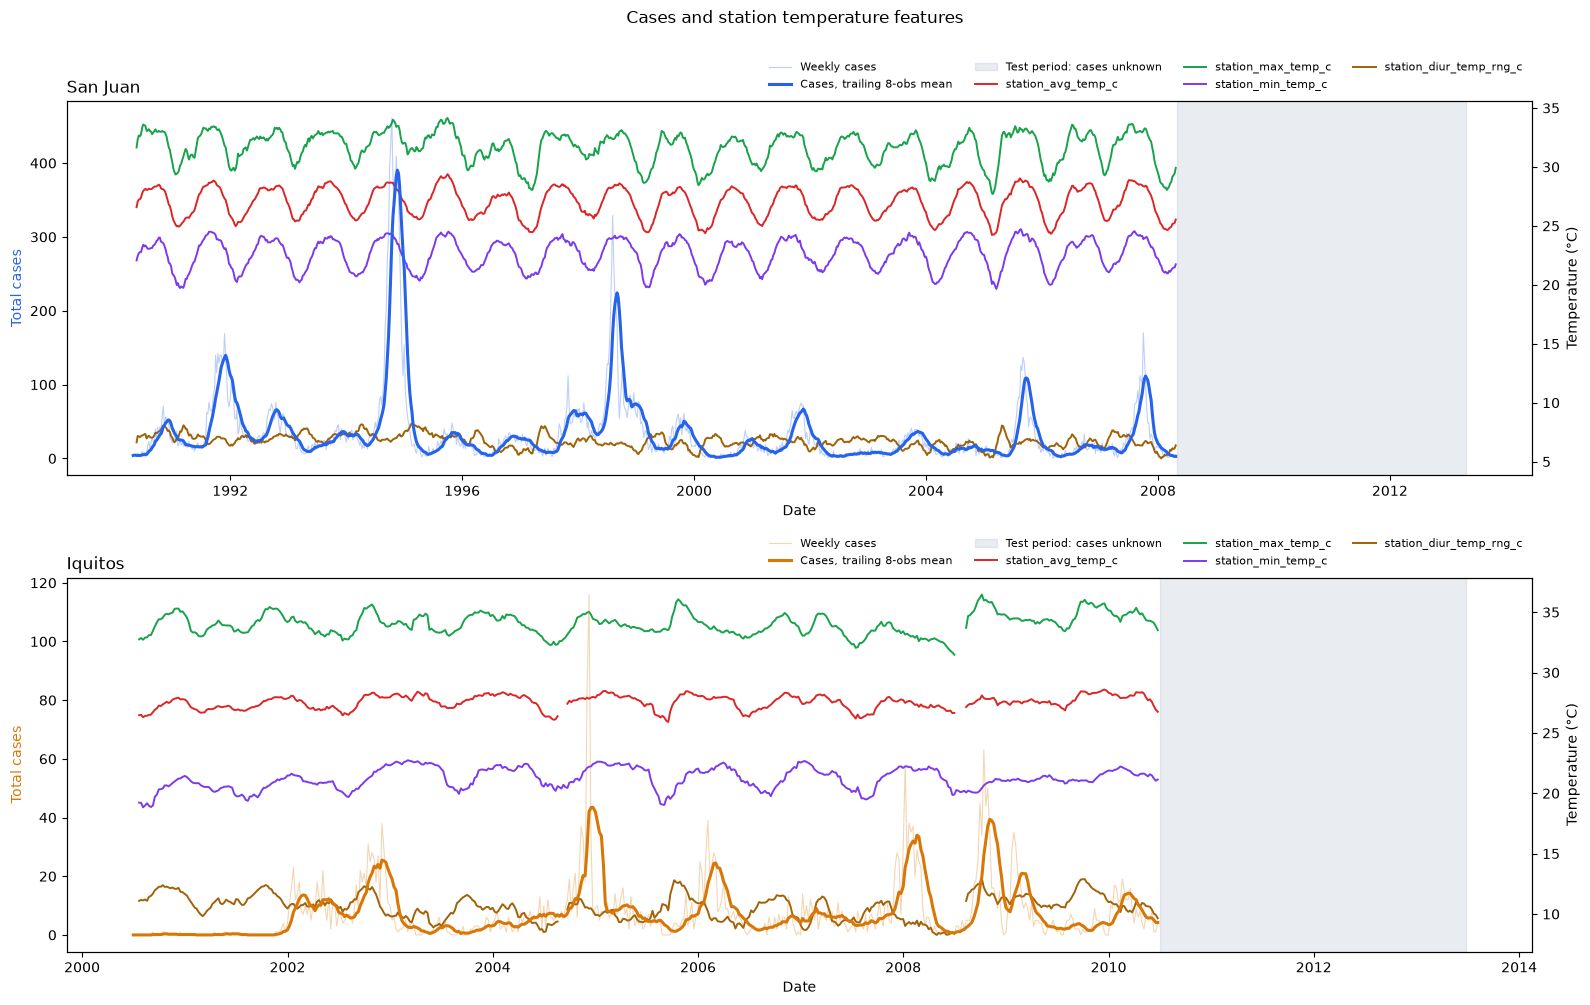

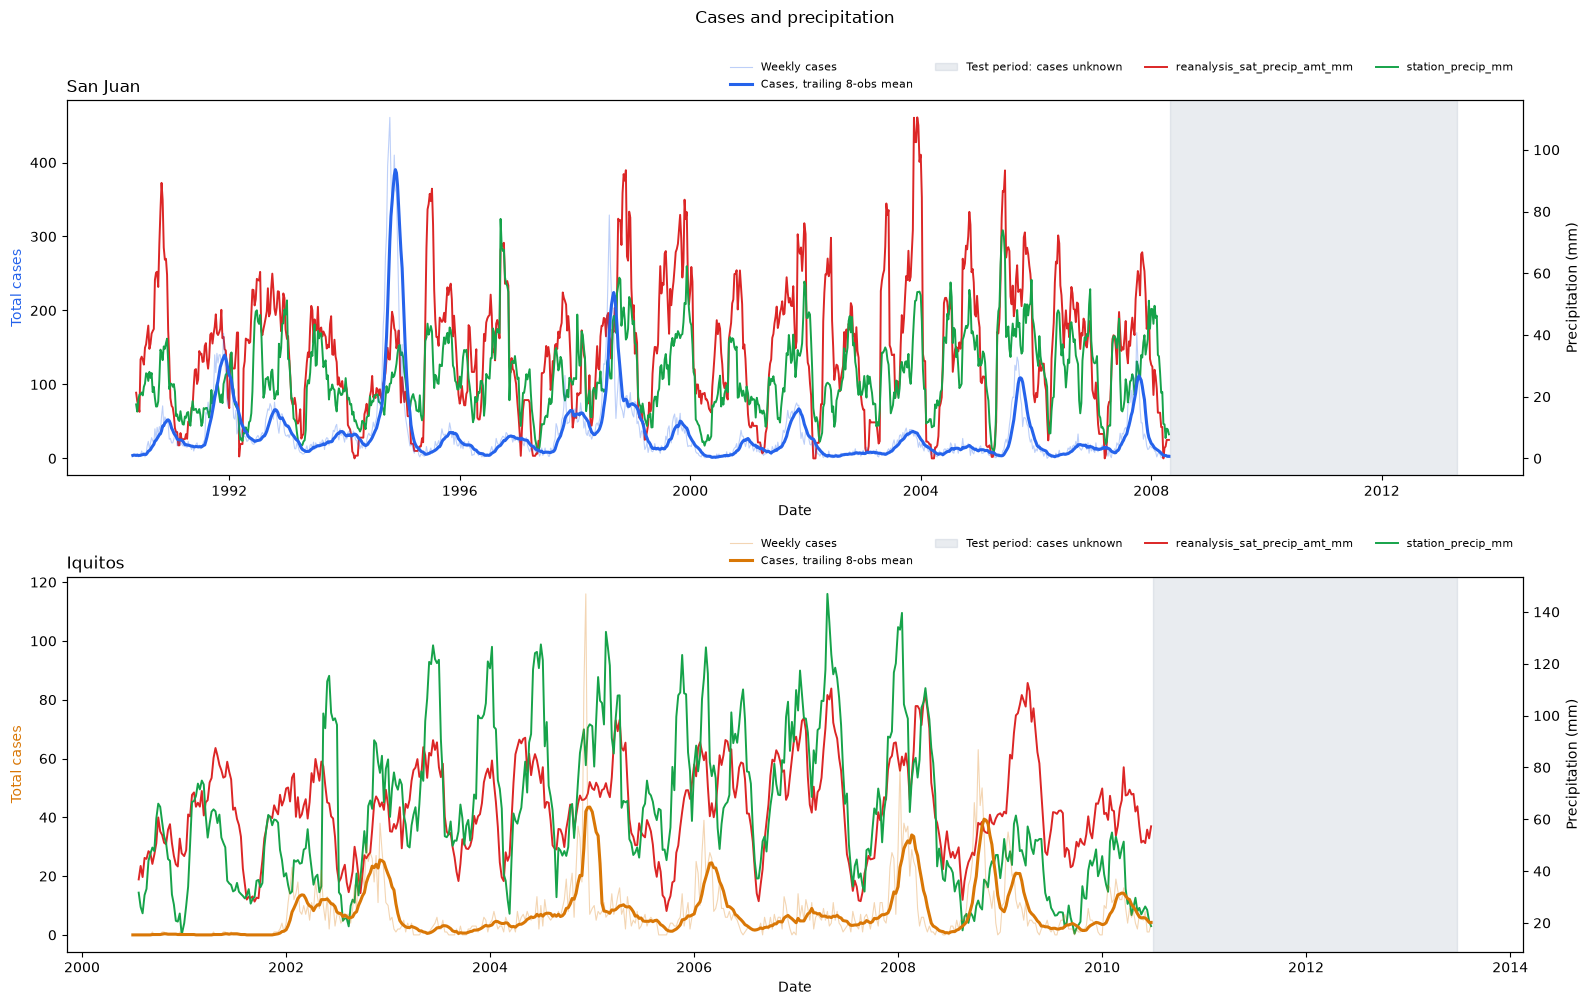

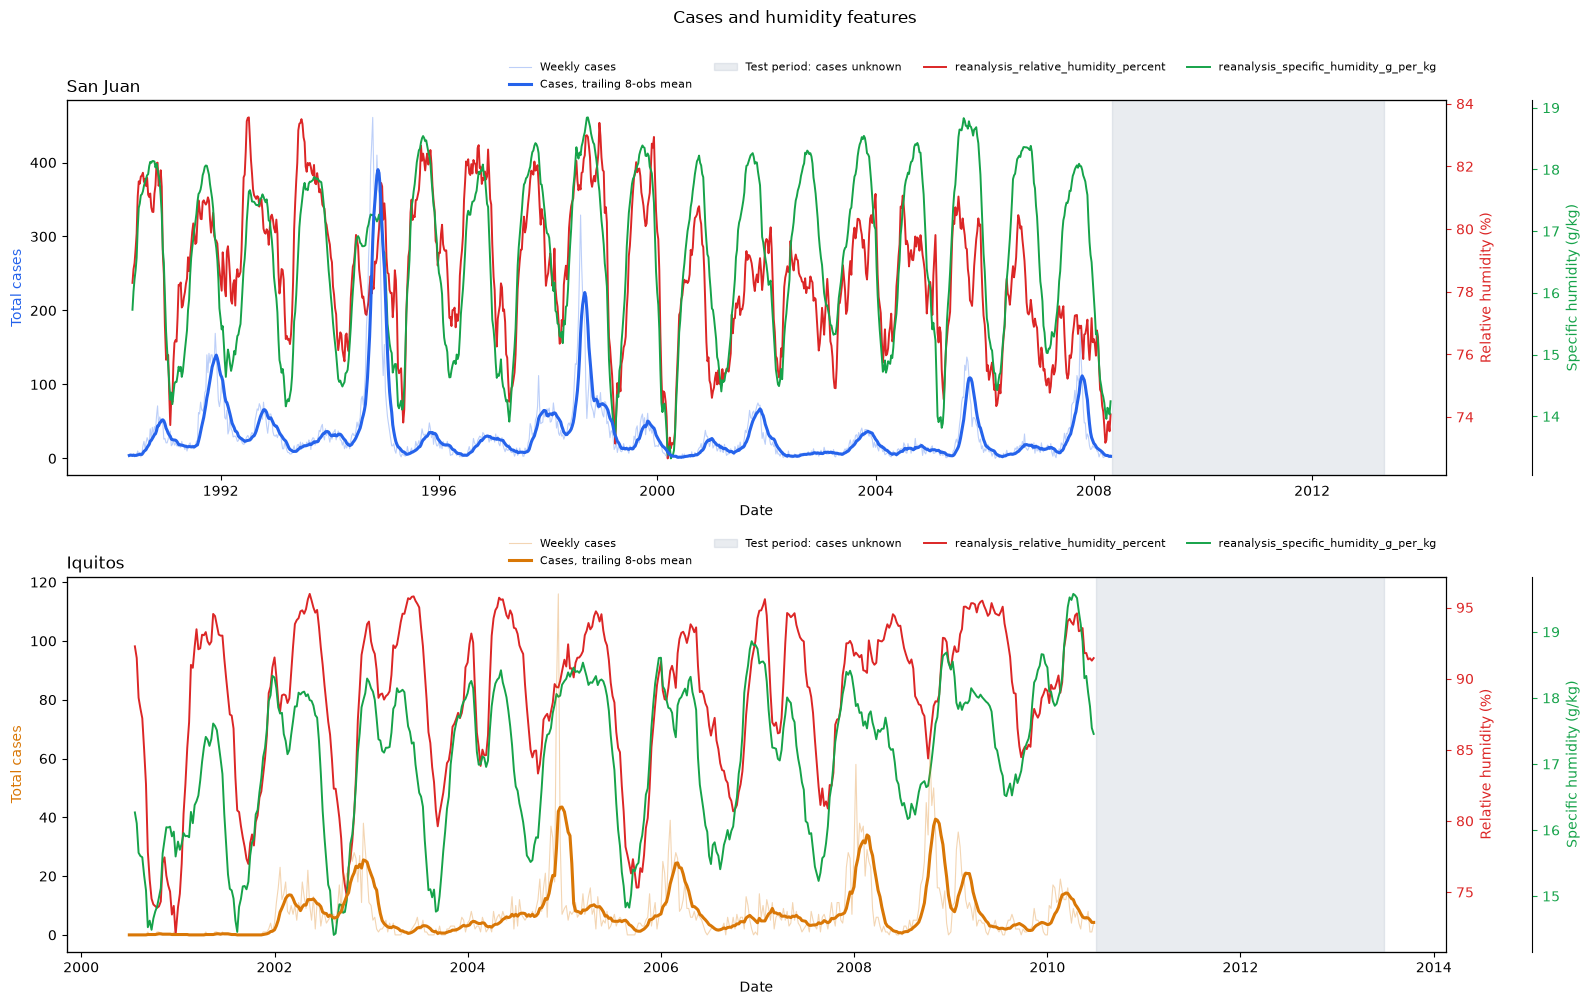

In [9]:
WINDOW = 8   # trailing observations used to smooth cases and weather
WEATHER_COLORS = ['#dc2626', '#16a34a', '#7c3aed', '#a16207', '#0d9488', '#525252']   # avoid the city colours

def plot_cases_and_weather(title, axis_groups):
    """Cases (left axis) and smoothed weather (right axis/axes) over time, one panel per city.
    axis_groups: list of (axis label, [features]); every group gets its own right-hand axis.
    The test period (cases unknown) is shaded grey."""
    all_features = [f for _, features in axis_groups for f in features]
    assert set(all_features) <= set(df_train_eda.columns), 'Unknown feature name.'
    colors = dict(zip(all_features, WEATHER_COLORS))
    fig, axes = plt.subplots(2, 1, figsize=(16, 10))
    for ax, city in zip(axes, CITIES):
        group = df_train_eda.loc[df_train_eda['city'].eq(city)].sort_values('week_start_date')
        dates = group['week_start_date']
        future = df_test_eda.loc[df_test_eda['city'].eq(city), 'week_start_date']
        ax.plot(dates, group[TARGET], color=COLORS[city], alpha=.3, lw=.8, label='Weekly cases')
        ax.plot(dates, group[TARGET].rolling(WINDOW, min_periods=1).mean(), color=COLORS[city], lw=2.2,
                label=f'Cases, trailing {WINDOW}-obs mean')
        ax.axvspan(future.min(), future.max(), color='#94a3b8', alpha=.2, label='Test period: cases unknown')
        ax.set_ylabel('Total cases', color=COLORS[city])
        ax.set_title(CITY_NAMES[city], loc='left')
        handles, labels = ax.get_legend_handles_labels()
        for position, (axis_label, features) in enumerate(axis_groups):
            twin = ax.twinx()
            twin.spines['right'].set_position(('outward', 62 * position))
            for feature in features:
                twin.plot(dates, group[feature].rolling(WINDOW, min_periods=WINDOW // 2).mean(),
                          color=colors[feature], lw=1.4, label=feature)
            twin.set_ylabel(axis_label)
            if len(features) == 1:   # colour the axis like its only line
                twin.yaxis.label.set_color(colors[features[0]])
                twin.tick_params(axis='y', colors=colors[features[0]])
            twin_handles, twin_labels = twin.get_legend_handles_labels()
            handles += twin_handles
            labels += twin_labels
        ax.set_zorder(len(axis_groups) + 1)    # draw cases above the weather lines
        ax.patch.set_visible(False)
        ax.legend(handles, labels, loc='lower right', bbox_to_anchor=(1, 1.0), ncol=4, fontsize=8, frameon=False)
        ax.set_xlabel('Date')
    fig.suptitle(title, y=1.0)
    plt.tight_layout()
    plt.show()

# Plot 1: cases with reanalysis temperature features
plot_cases_and_weather('Cases and reanalysis temperature features', [('Temperature (°C)', [
    'reanalysis_air_temp_c', 'reanalysis_avg_temp_c', 'reanalysis_dew_point_temp_c',
    'reanalysis_max_air_temp_c', 'reanalysis_min_air_temp_c', 'reanalysis_tdtr_c'])])

# Plot 2: cases with station temperature features
plot_cases_and_weather('Cases and station temperature features', [('Temperature (°C)', [
    'station_avg_temp_c', 'station_max_temp_c', 'station_min_temp_c', 'station_diur_temp_rng_c'])])

# Plot 3: cases with precipitation (satellite/reanalysis and station)
plot_cases_and_weather('Cases and precipitation', [('Precipitation (mm)', [
    'reanalysis_sat_precip_amt_mm', 'station_precip_mm'])])

# Plot 4: cases with humidity features (different units, so one right-hand axis each)
plot_cases_and_weather('Cases and humidity features', [
    ('Relative humidity (%)', ['reanalysis_relative_humidity_percent']),
    ('Specific humidity (g/kg)', ['reanalysis_specific_humidity_g_per_kg'])])

In [10]:
print('Largest observed weekly counts (inspect, do not automatically remove):')
display(pd.concat([g.nlargest(5, TARGET)[['city', 'week_start_date', TARGET]]
                   for _, g in df_train.groupby('city')], ignore_index=True))

Largest observed weekly counts (inspect, do not automatically remove):


,city,week_start_date,total_cases
0,iq,2004-12-09,116
1,iq,2004-12-02,83
2,iq,2008-10-14,63
3,iq,2008-01-08,58
4,iq,2008-10-28,50
5,sj,1994-10-15,461
6,sj,1994-10-08,426
7,sj,1994-11-12,410
8,sj,1994-10-01,395
9,sj,1994-10-22,381


**Observations (§7).** The largest `sj` weeks are all in Sept–Nov 1994, and the largest `iq` weeks are in Dec 2004 (116 and 83 cases), followed by smaller peaks in 2008. These are single dominant outbreaks, not isolated data errors, so they are kept. The baseline moves a lot over the years (explored in §14).

## 8. Seasonality

Uses the supplied `weekofyear`. Pooled summaries mix full years with partial first/last years, so they are indicative only. The first figure shows the typical year (mean, median, inter-quartile range); the second shows every year × week to reveal how consistent the seasonal timing and size of outbreaks are. Dashed grey lines mark month boundaries within each year.

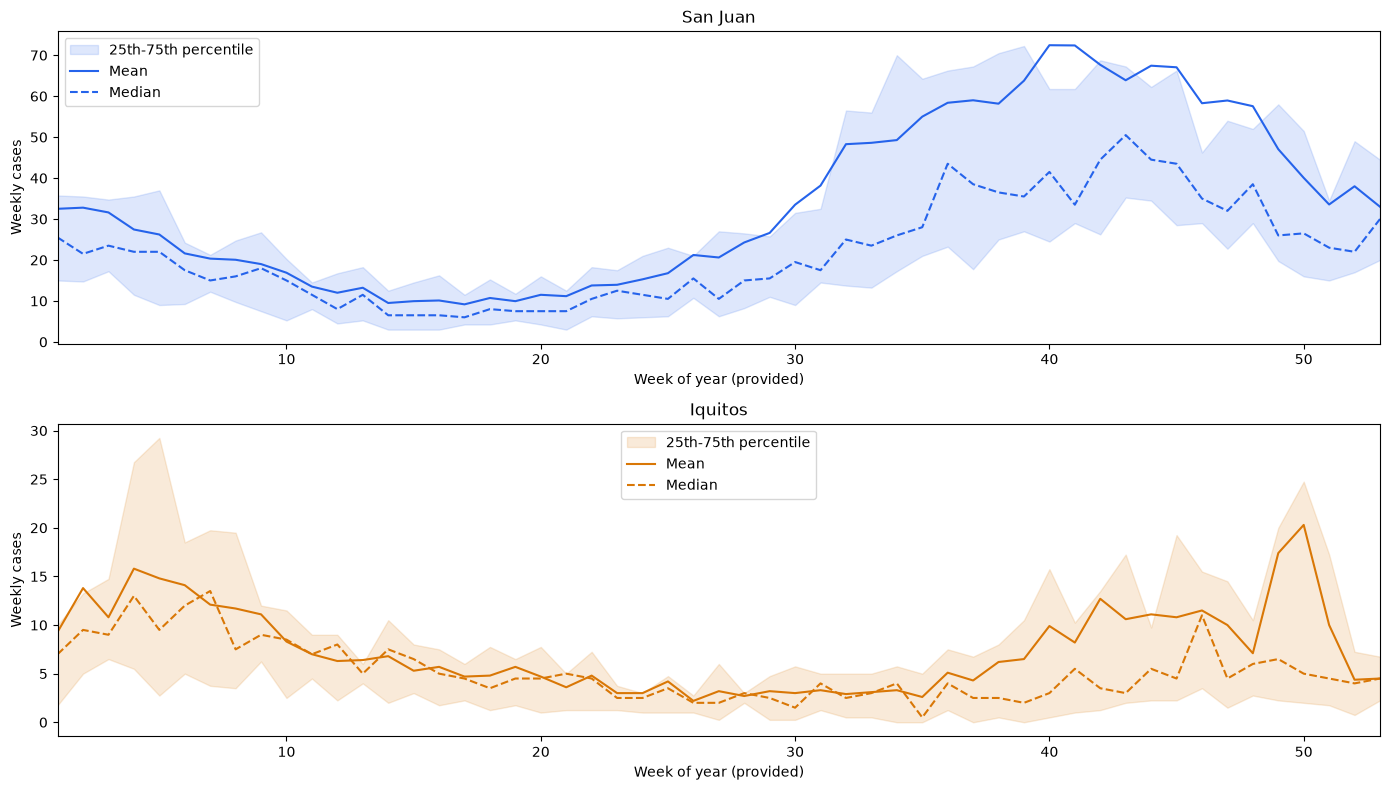

In [11]:
seasonality = df_train.groupby(['city', 'weekofyear'])[TARGET].agg(
    mean='mean', median='median', q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75), n='size'
).reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, city in zip(axes, CITIES):
    group = seasonality.loc[seasonality['city'].eq(city)]
    ax.fill_between(group['weekofyear'], group['q25'], group['q75'], color=COLORS[city], alpha=.15, label='25th-75th percentile')
    ax.plot(group['weekofyear'], group['mean'], color=COLORS[city], label='Mean')
    ax.plot(group['weekofyear'], group['median'], color=COLORS[city], linestyle='--', label='Median')
    ax.set(title=CITY_NAMES[city], xlabel='Week of year (provided)', ylabel='Weekly cases', xlim=(1, 53))
    ax.legend()
plt.tight_layout()
plt.show()

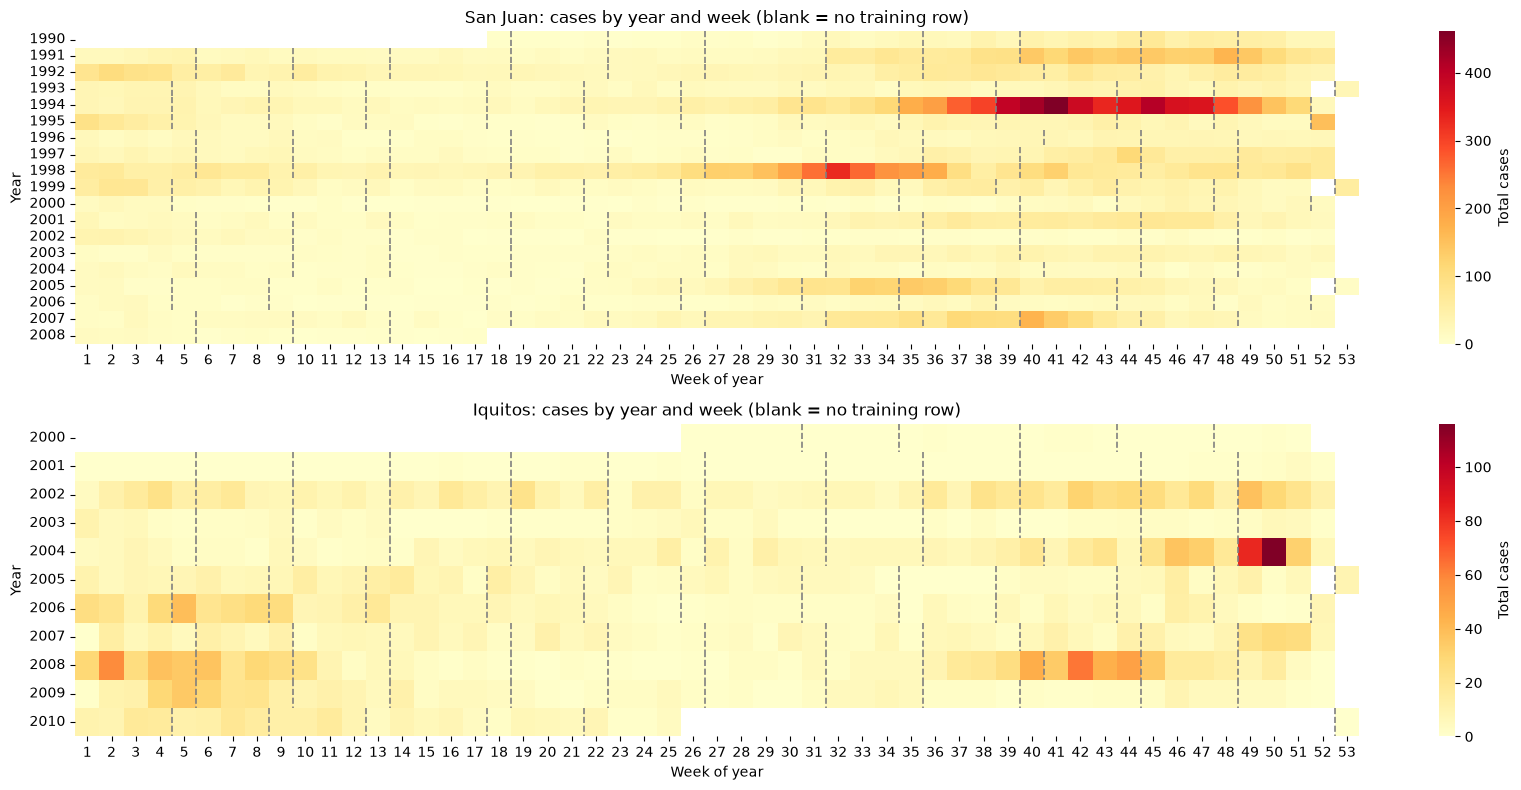

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(17, 8))
for ax, city in zip(axes, CITIES):
    city_data = df_train.loc[df_train['city'].eq(city)]
    pivot = city_data.pivot(index='year', columns='weekofyear', values=TARGET).reindex(columns=range(1, 54))
    sns.heatmap(pivot, cmap='YlOrRd', mask=pivot.isna(), ax=ax, cbar_kws={'label': 'Total cases'})
    # month separators drawn within each year's row
    for row_position, year in enumerate(pivot.index):
        year_data = city_data.loc[city_data['year'].eq(year)].sort_values('weekofyear')
        months = year_data['week_start_date'].dt.to_period('M')
        boundary_weeks = year_data.loc[months.ne(months.shift()), 'weekofyear'].iloc[1:]
        ax.vlines(boundary_weeks.to_numpy() - 1, row_position, row_position + 1,
                  colors='gray', linestyles='--', linewidth=1.2)
    ax.set(title=f'{CITY_NAMES[city]}: cases by year and week (blank = no training row)',
           xlabel='Week of year', ylabel='Year')
plt.tight_layout()
plt.show()

**Observations (§8).** `sj` shows a clear annual pattern with the main peak typically between weeks 35 and 48 (the annual table in §14 lists each year's peak week; a few years peak in weeks 52–2 instead). `iq` is much less regular, with peaks at different times of year in different years. Size varies hugely between years in both cities.

## 9. Environmental distributions by city

Density-normalised histograms (cities have different sample sizes). Missing values are omitted, not filled. Clearly different distributions mean the same weather value can describe a different climate in each city, which argues for city-aware modelling.

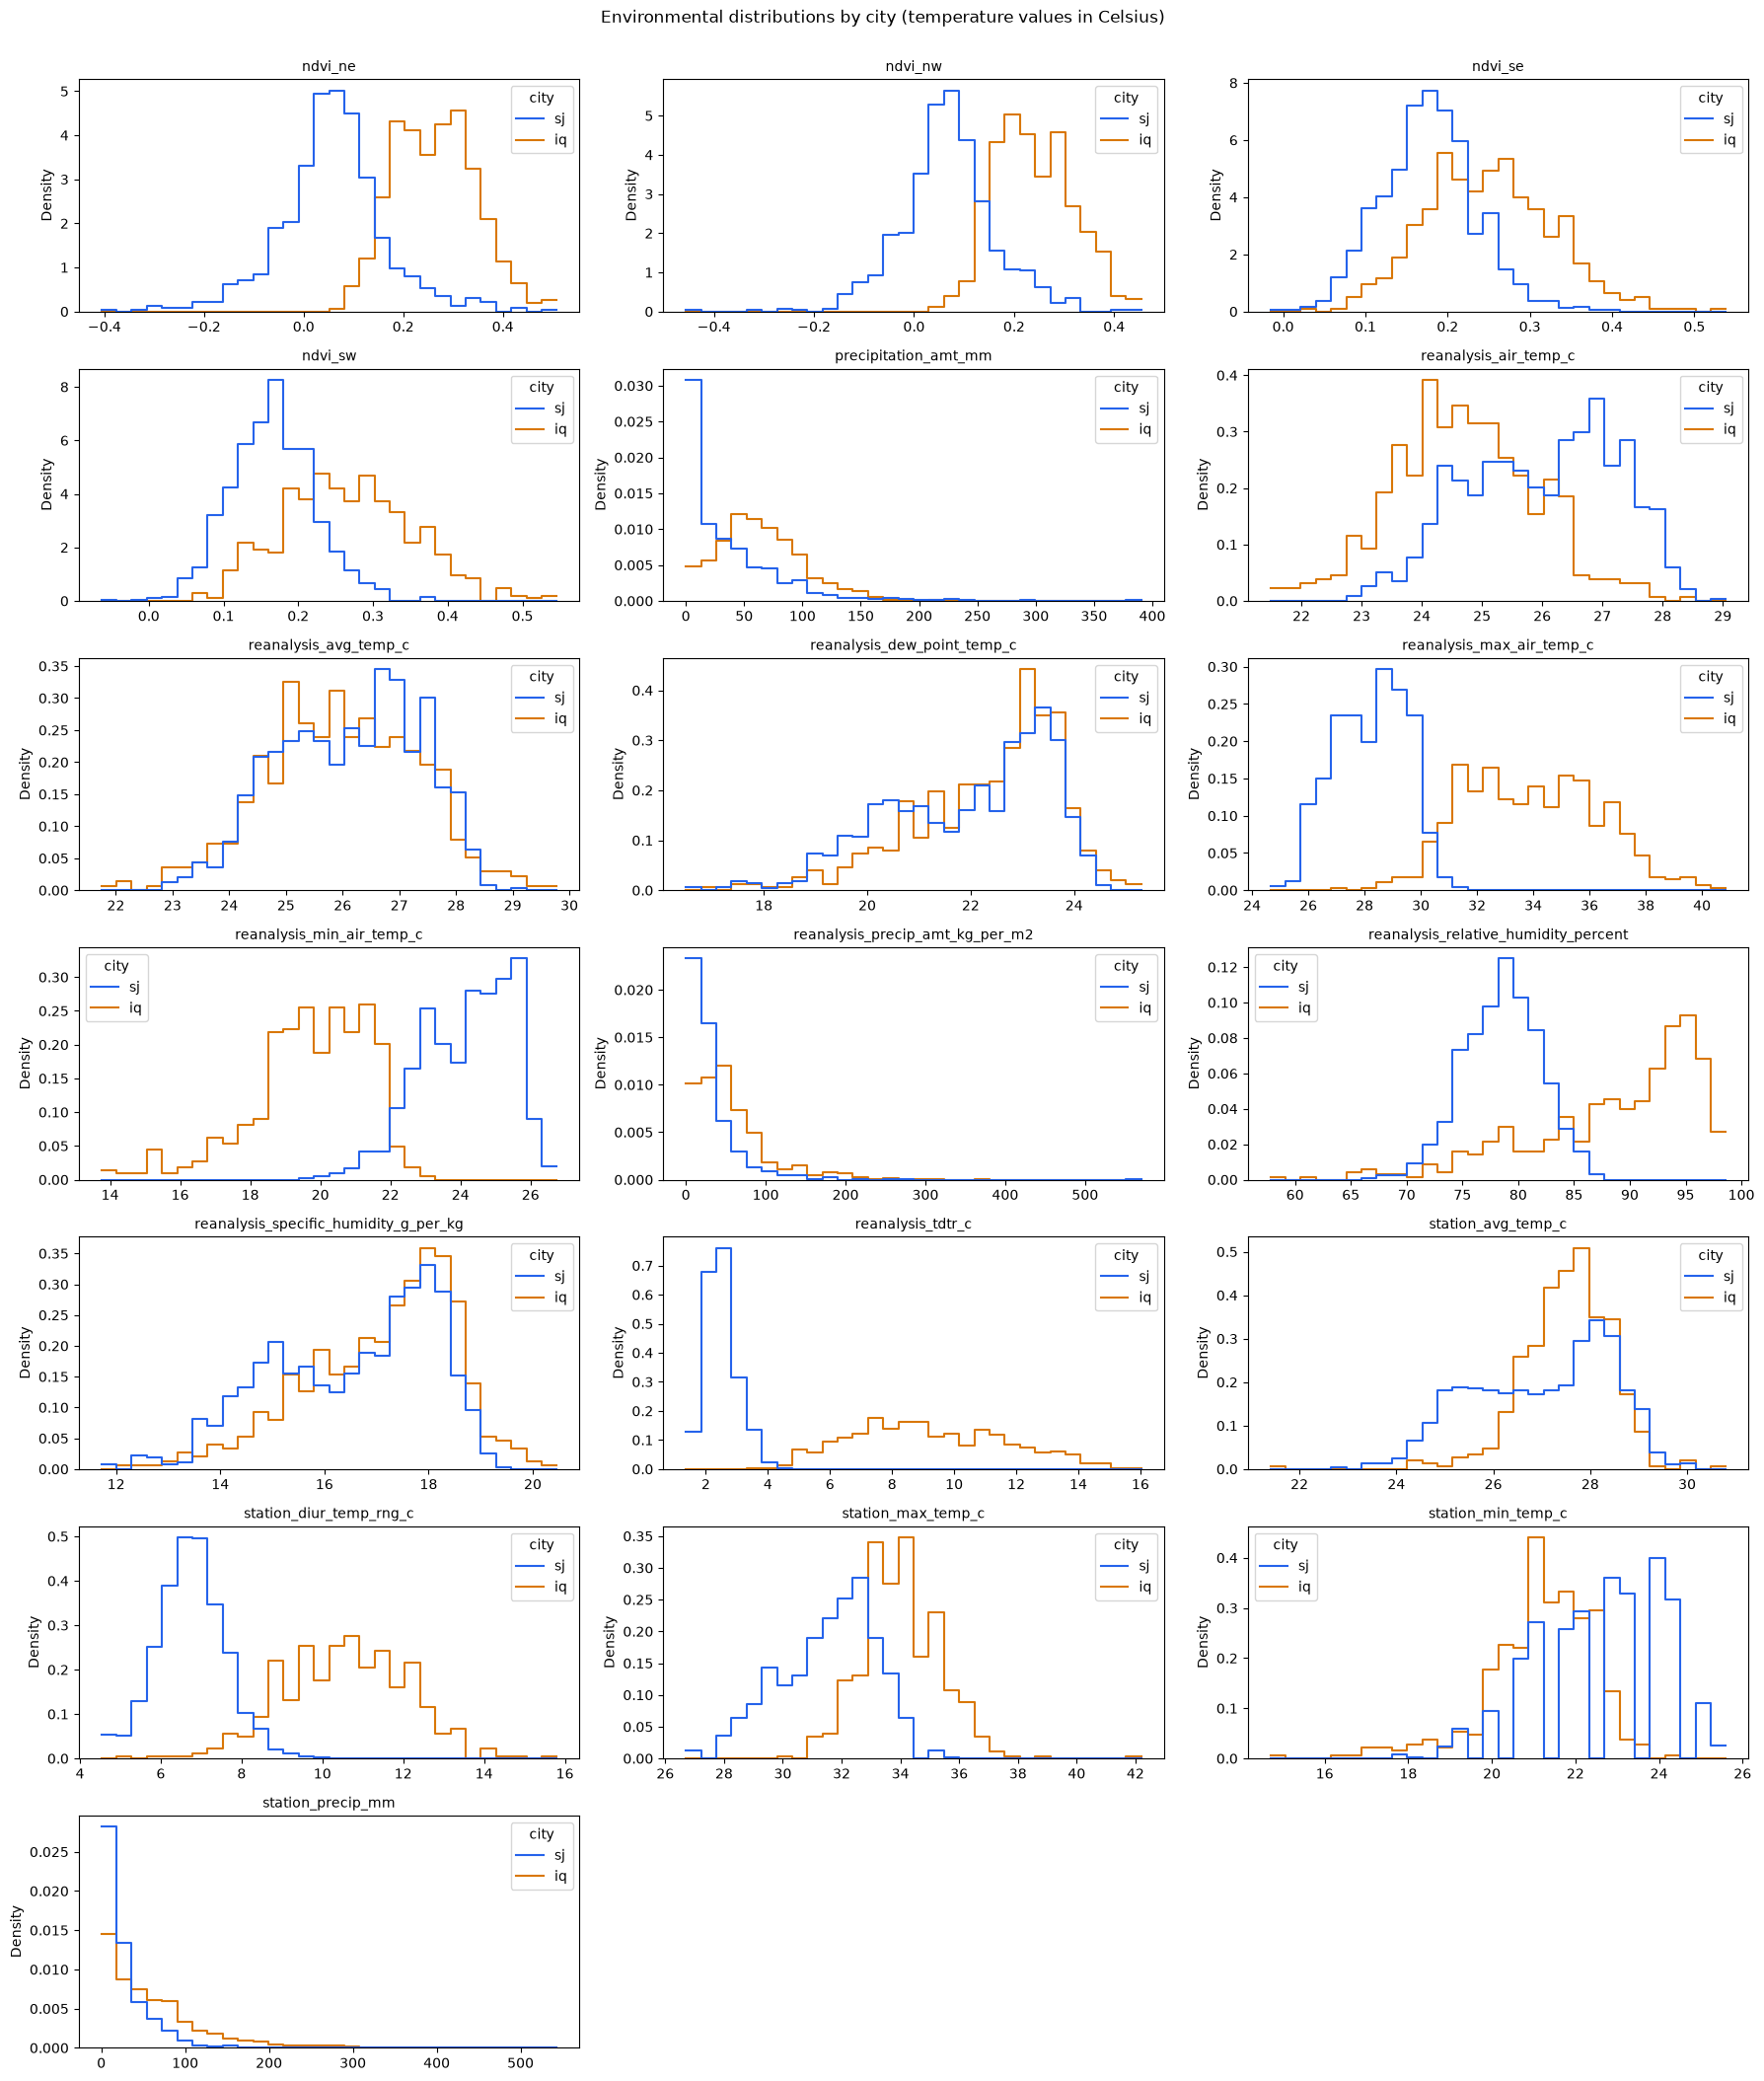

In [13]:
ncols = 3
nrows = int(np.ceil(len(plot_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3 * nrows))
for ax, feature in zip(axes.flat, plot_features):
    sns.histplot(data=df_train_eda, x=feature, hue='city', hue_order=CITIES, palette=COLORS, bins=30,
                 stat='density', common_norm=False, element='step', fill=False, ax=ax)
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel('')
for ax in axes.flat[len(plot_features):]:
    ax.set_visible(False)
fig.suptitle('Environmental distributions by city (temperature values in Celsius)', y=1.002)
plt.tight_layout()
plt.show()

**Observations (§9).** The cities have visibly different climates. For example `ndvi_ne` averages 0.26 in `iq` vs 0.06 in `sj`, and median station precipitation is about 45 mm in `iq` vs about 18 mm in `sj`. A given weather value therefore means something different in each city.

## 10. Same-week correlations with cases

Spearman (rank, monotonic) and Pearson (linear) correlations between each feature and `total_cases`, computed **within each city** on pairwise-complete rows (at least 30 pairs). Computing within city avoids mixing between-city level differences into the relationship (Simpson's-paradox-style effects). The target has no missing values, so the pair count equals the number of non-missing feature values.

These are same-week associations only; they do not show predictive value on future data or causation.

city                                       sj               iq         
method                                pearson spearman pearson spearman
reanalysis_specific_humidity_g_per_kg   0.208    0.263   0.236    0.372
reanalysis_dew_point_temp_c             0.204    0.258   0.230    0.368
reanalysis_min_air_temp_c               0.188    0.234   0.215    0.317
station_min_temp_c                      0.177    0.192   0.212    0.273
station_avg_temp_c                      0.197    0.187   0.113    0.188
reanalysis_relative_humidity_percent    0.144    0.198   0.130    0.201
reanalysis_precip_amt_kg_per_m2         0.107    0.222   0.101    0.231
reanalysis_air_temp_c                   0.182    0.207   0.097    0.122
reanalysis_tdtr_c                      -0.068   -0.162  -0.134   -0.195
reanalysis_max_air_temp_c               0.195    0.202  -0.056   -0.106
reanalysis_avg_temp_c                   0.175    0.201   0.080    0.099
station_max_temp_c                      0.190    0.154   0.075    0.053
precipitation_amt_mm                    0.060    0.128   0.090    0.128
station_precip_mm                       0.052    0.103   0.043    0.091
ndvi_nw                                 0.075    0.115  -0.010   -0.042
station_diur_temp_rng_c                 0.035    0.027  -0.058   -0.118
ndvi_ne                                 0.038    0.070   0.020   -0.037
ndvi_se                                 0.001   -0.000  -0.041   -0.094
ndvi_sw                                -0.000   -0.013   0.033   -0.047

,sj,iq
valid_feature_target_pairs,,
reanalysis_specific_humidity_g_per_kg,930,516
reanalysis_dew_point_temp_c,930,516
reanalysis_min_air_temp_c,930,516
station_min_temp_c,930,512
station_avg_temp_c,930,483
reanalysis_relative_humidity_percent,930,516
reanalysis_precip_amt_kg_per_m2,930,516
reanalysis_air_temp_c,930,516
reanalysis_tdtr_c,930,516


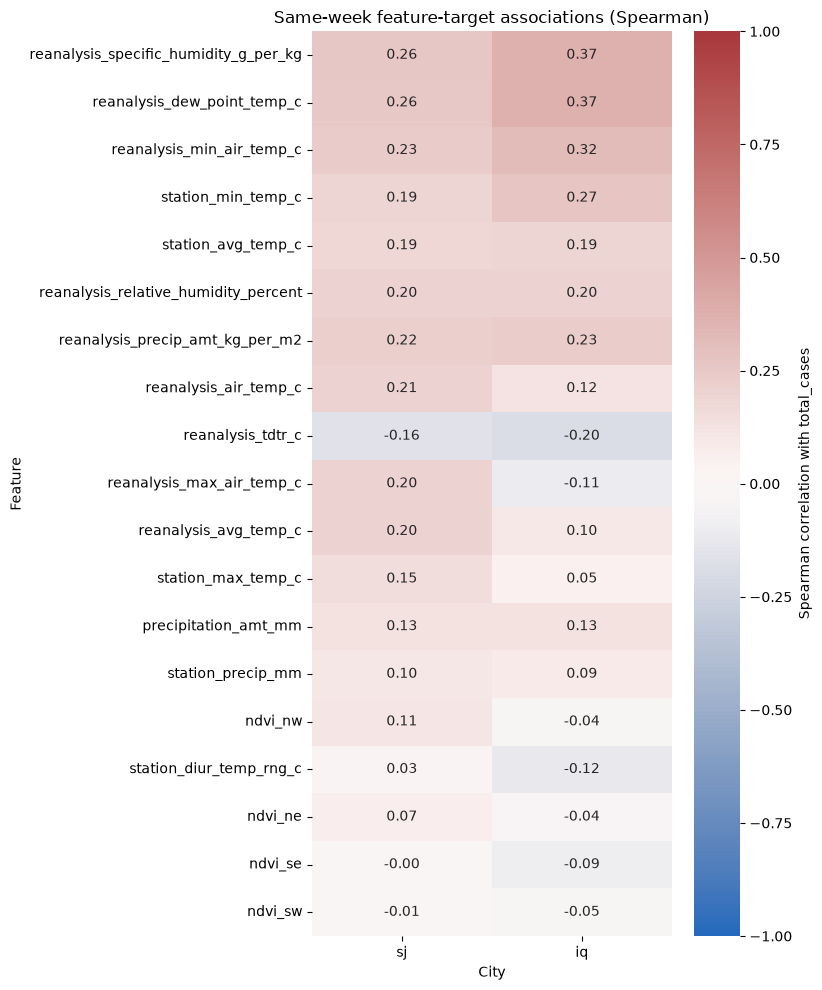

In [14]:
assert df_train[TARGET].notna().all()
target_correlations, pair_counts = {}, {}
for city in CITIES:
    group = df_train_eda.loc[df_train_eda['city'].eq(city), plot_features + [TARGET]]
    for method in ['pearson', 'spearman']:
        target_correlations[(city, method)] = group.corr(method=method, min_periods=30)[TARGET].drop(TARGET)
    pair_counts[city] = group[plot_features].notna().sum()

corr_table = pd.DataFrame(target_correlations)
corr_table.columns = pd.MultiIndex.from_tuples(corr_table.columns, names=['city', 'method'])
order = corr_table.abs().mean(axis=1).sort_values(ascending=False).index   # strongest first, both methods
display(corr_table.loc[order].round(3))
display(pd.DataFrame(pair_counts).loc[order].rename_axis('valid_feature_target_pairs'))

spearman_table = pd.DataFrame({city: target_correlations[(city, 'spearman')] for city in CITIES}).loc[order]
fig, ax = plt.subplots(figsize=(8, 10))
sns.heatmap(spearman_table, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0,
            cbar_kws={'label': 'Spearman correlation with total_cases'}, ax=ax)
ax.set(title='Same-week feature-target associations (Spearman)', xlabel='City', ylabel='Feature')
plt.tight_layout()
plt.show()

**Observations (§10).** All same-week associations are weak. The best are specific humidity (Spearman 0.26 `sj`, 0.37 `iq`), dew point and minimum temperature. NDVI features are close to zero. Some features have opposite signs in the two cities (for example `reanalysis_max_air_temp_c`: +0.20 in `sj`, −0.11 in `iq`).

## 11. Individual relationships and feature redundancy

Scatterplots show every observation and can reveal shapes a single coefficient hides (thresholds, saturation, clusters). The lower-triangle Spearman matrices show which measurements carry overlapping information. High correlation alone is not a reason to drop a feature.

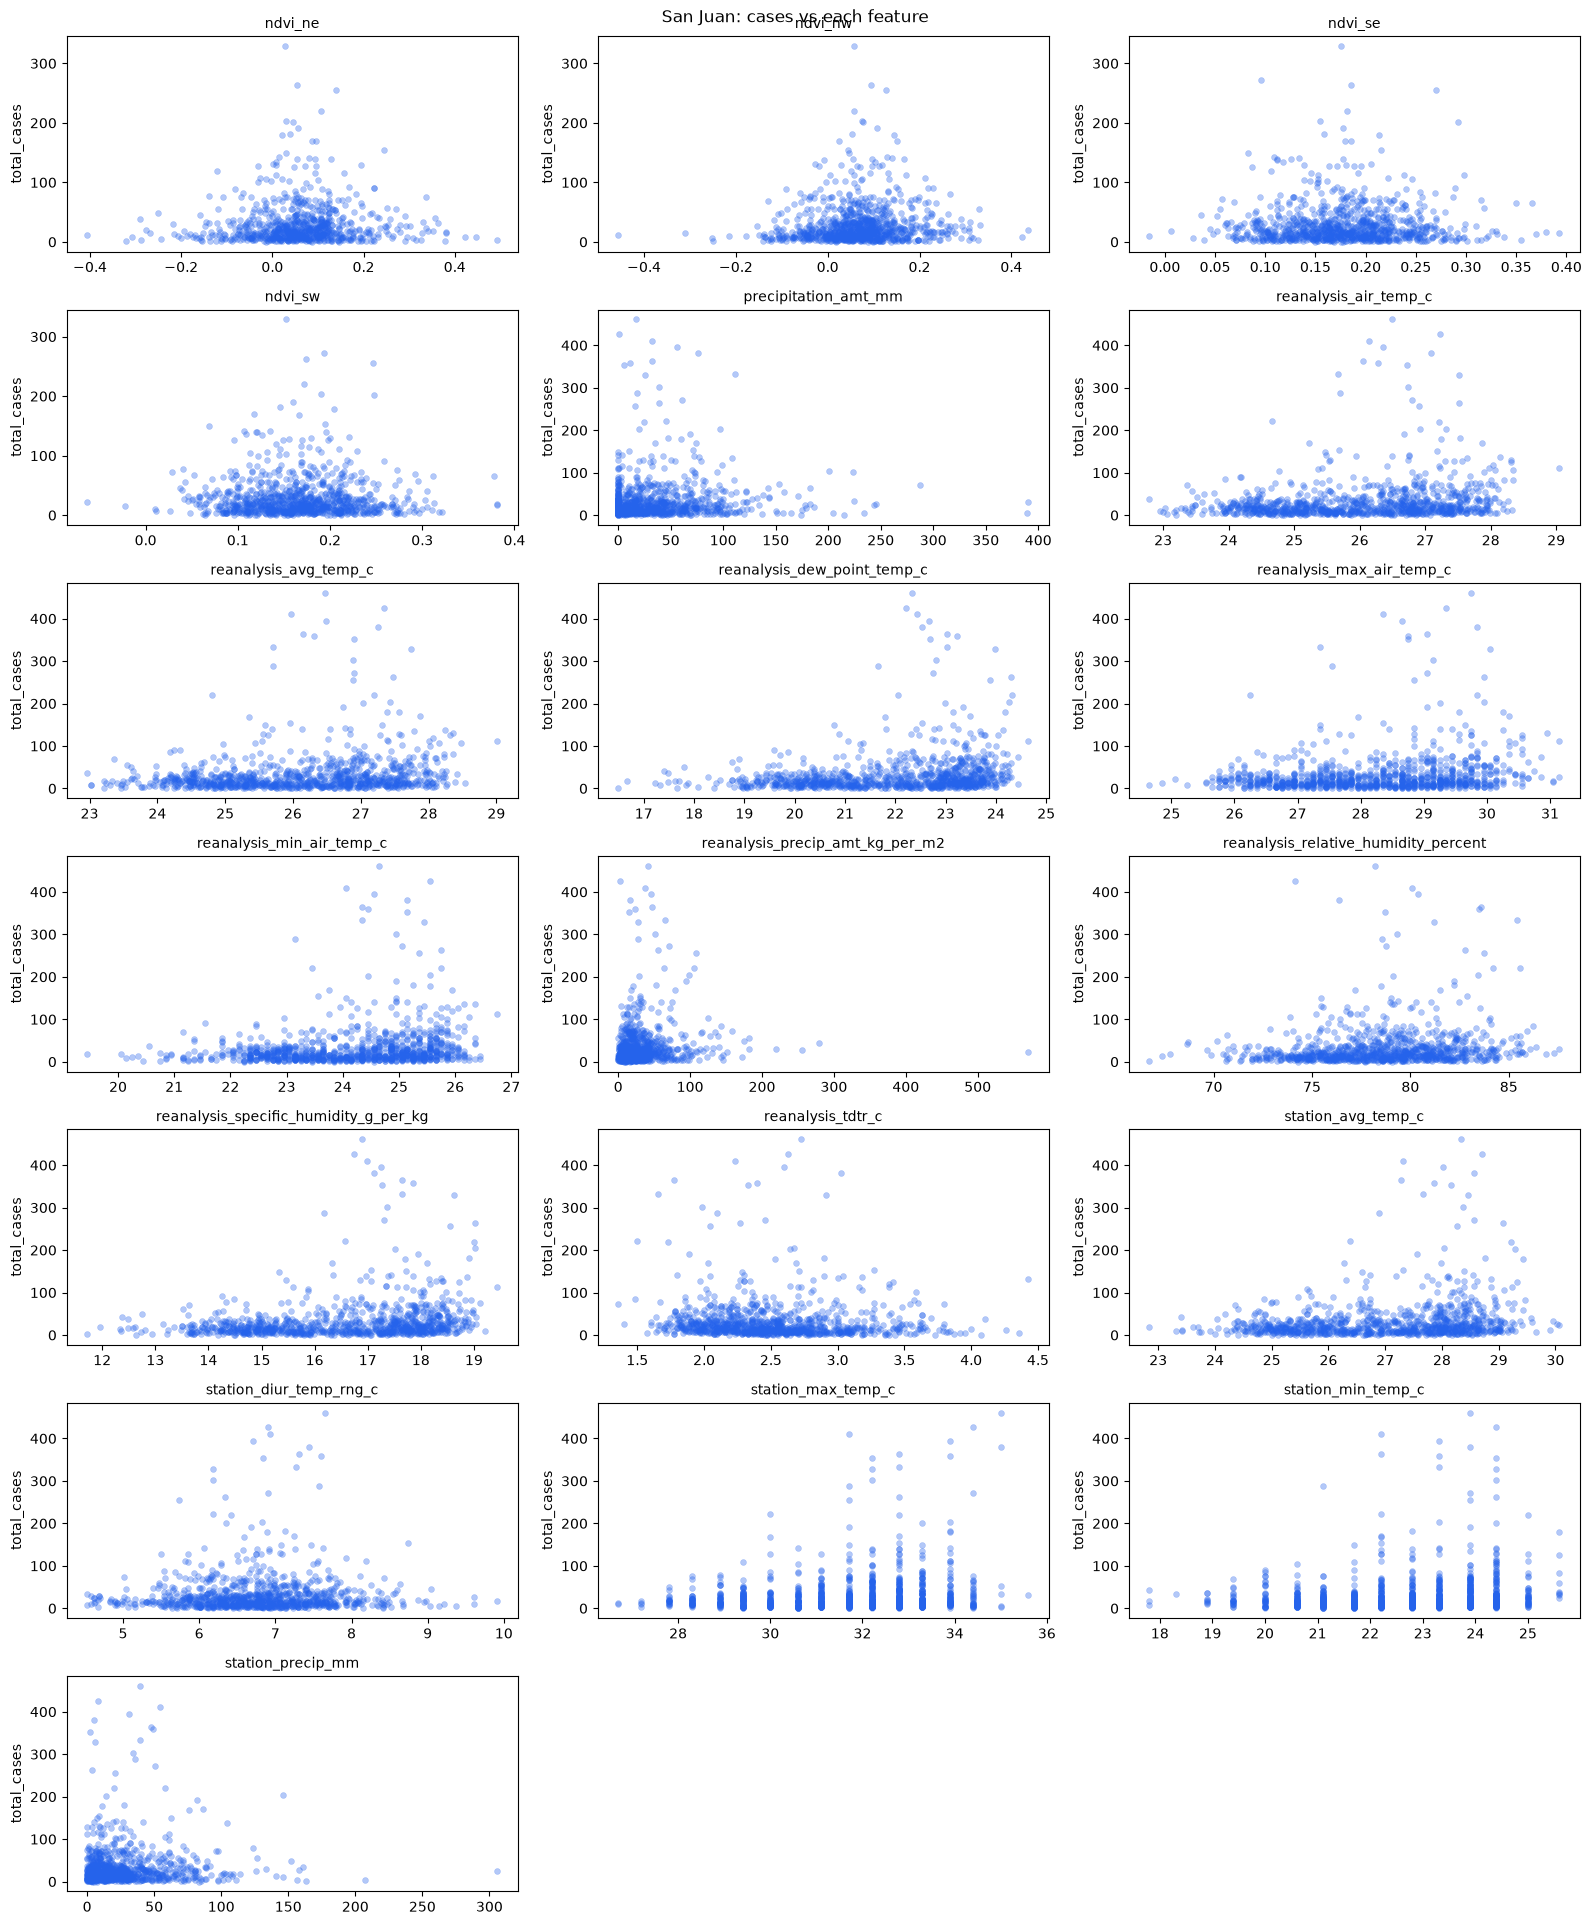

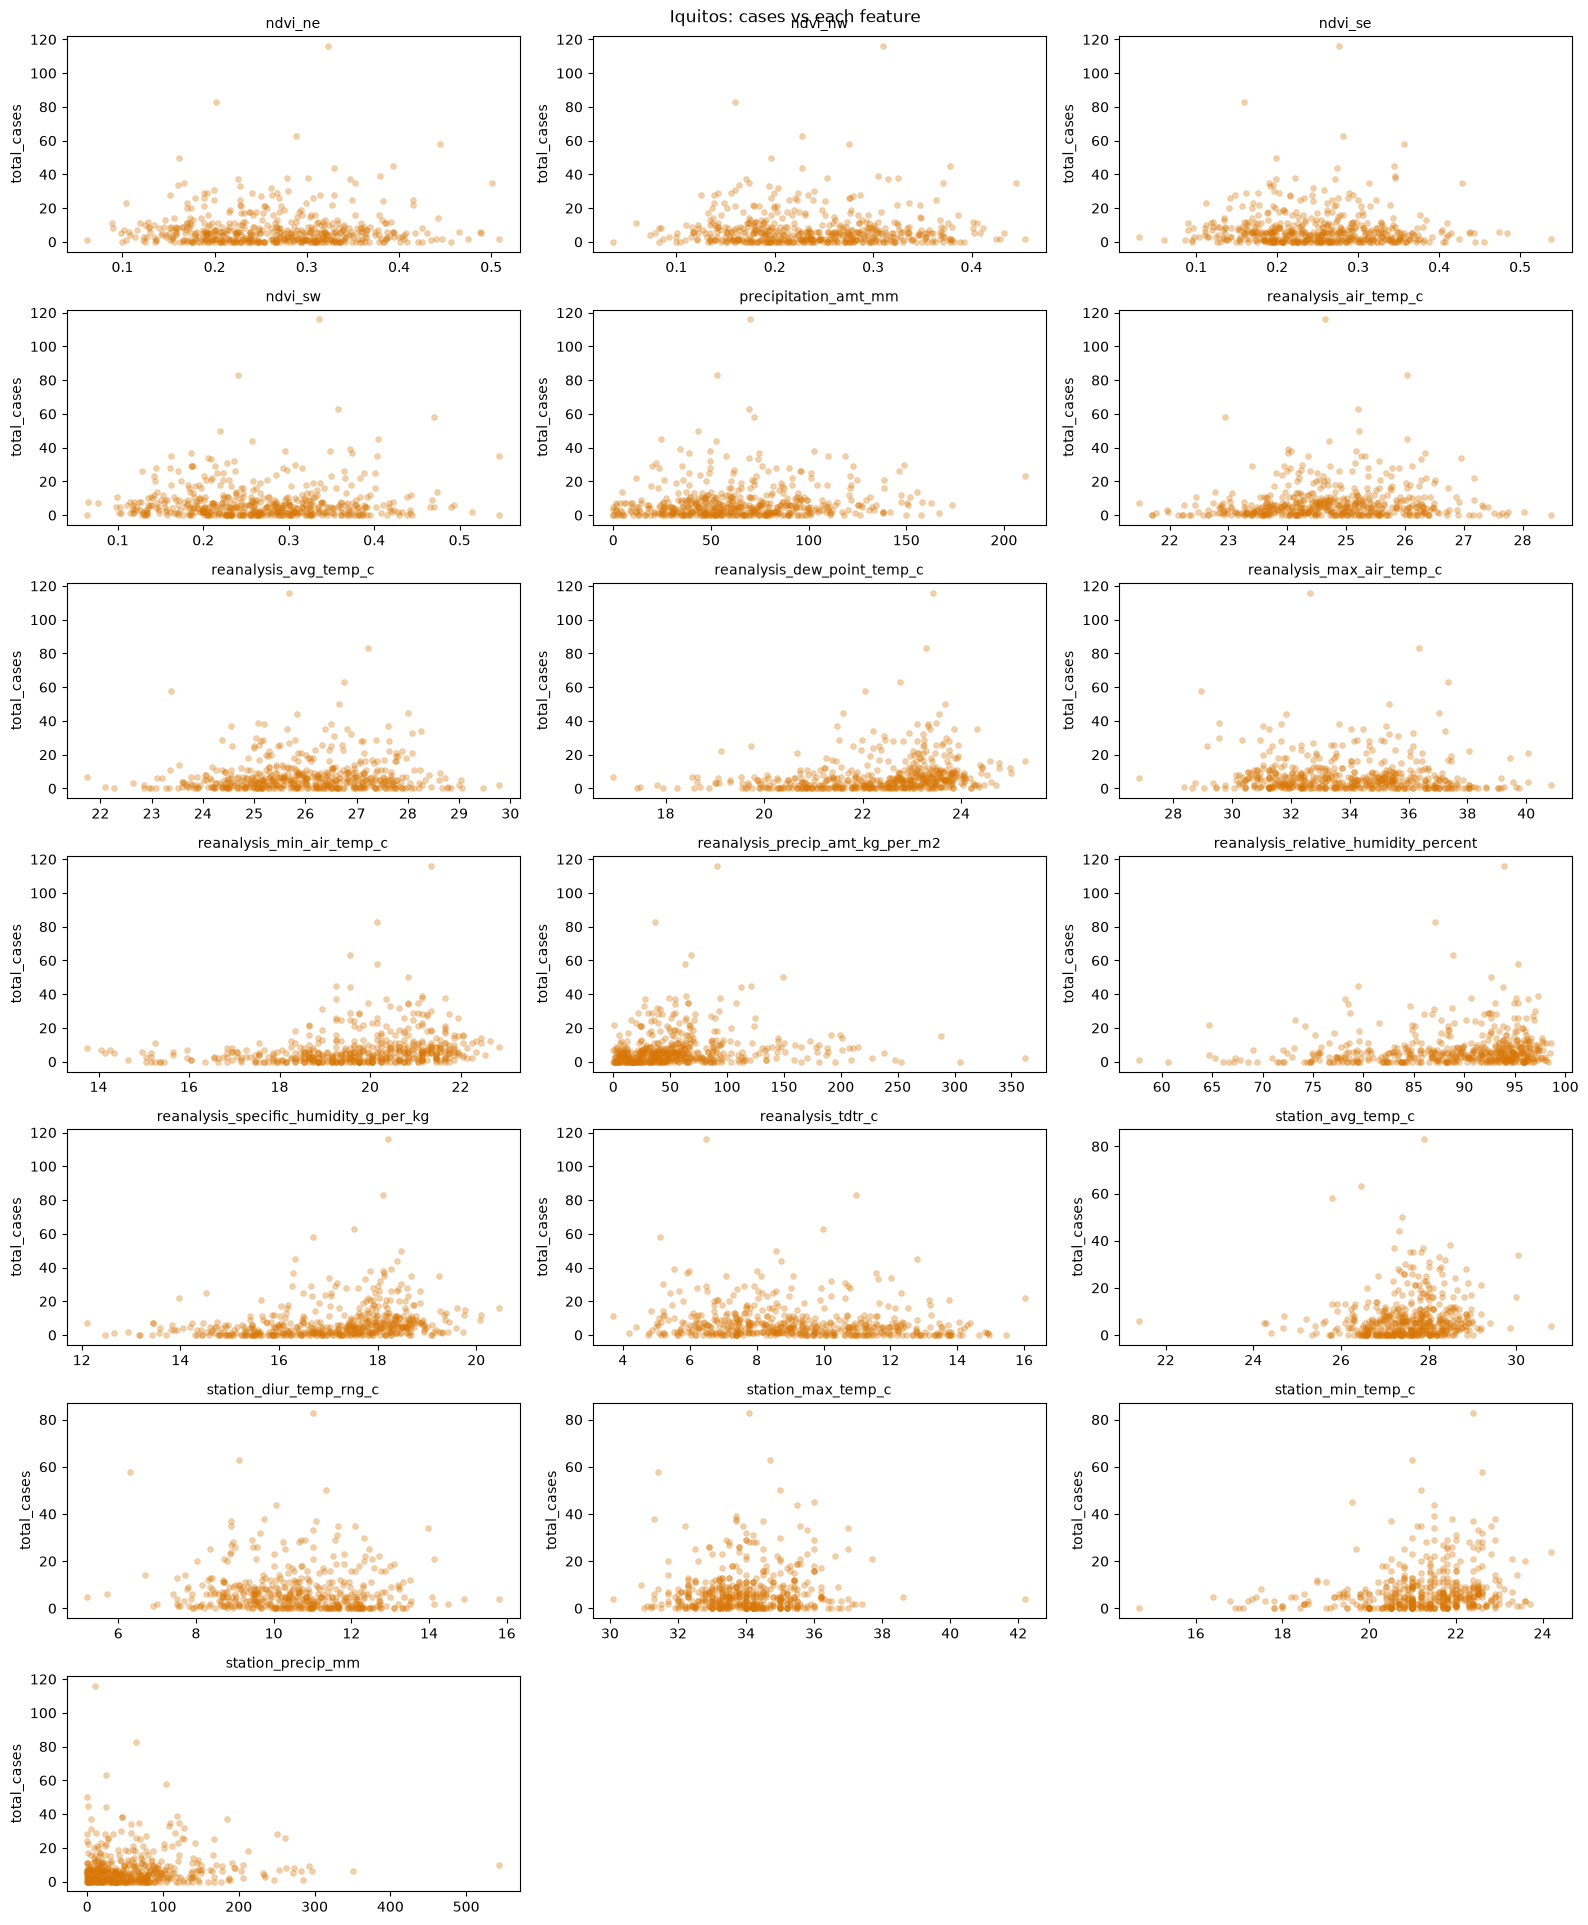

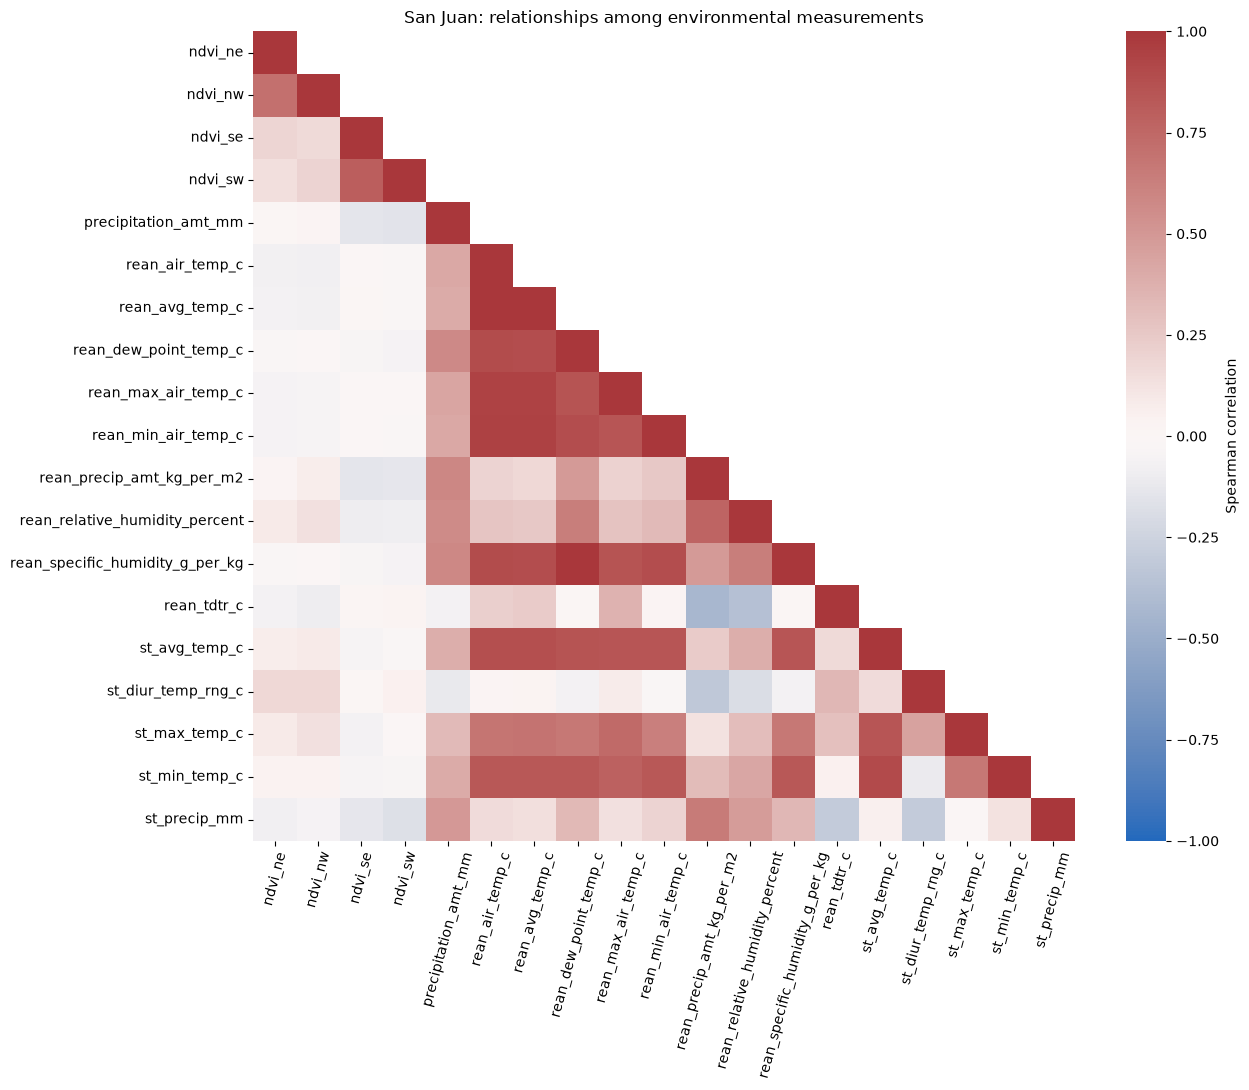

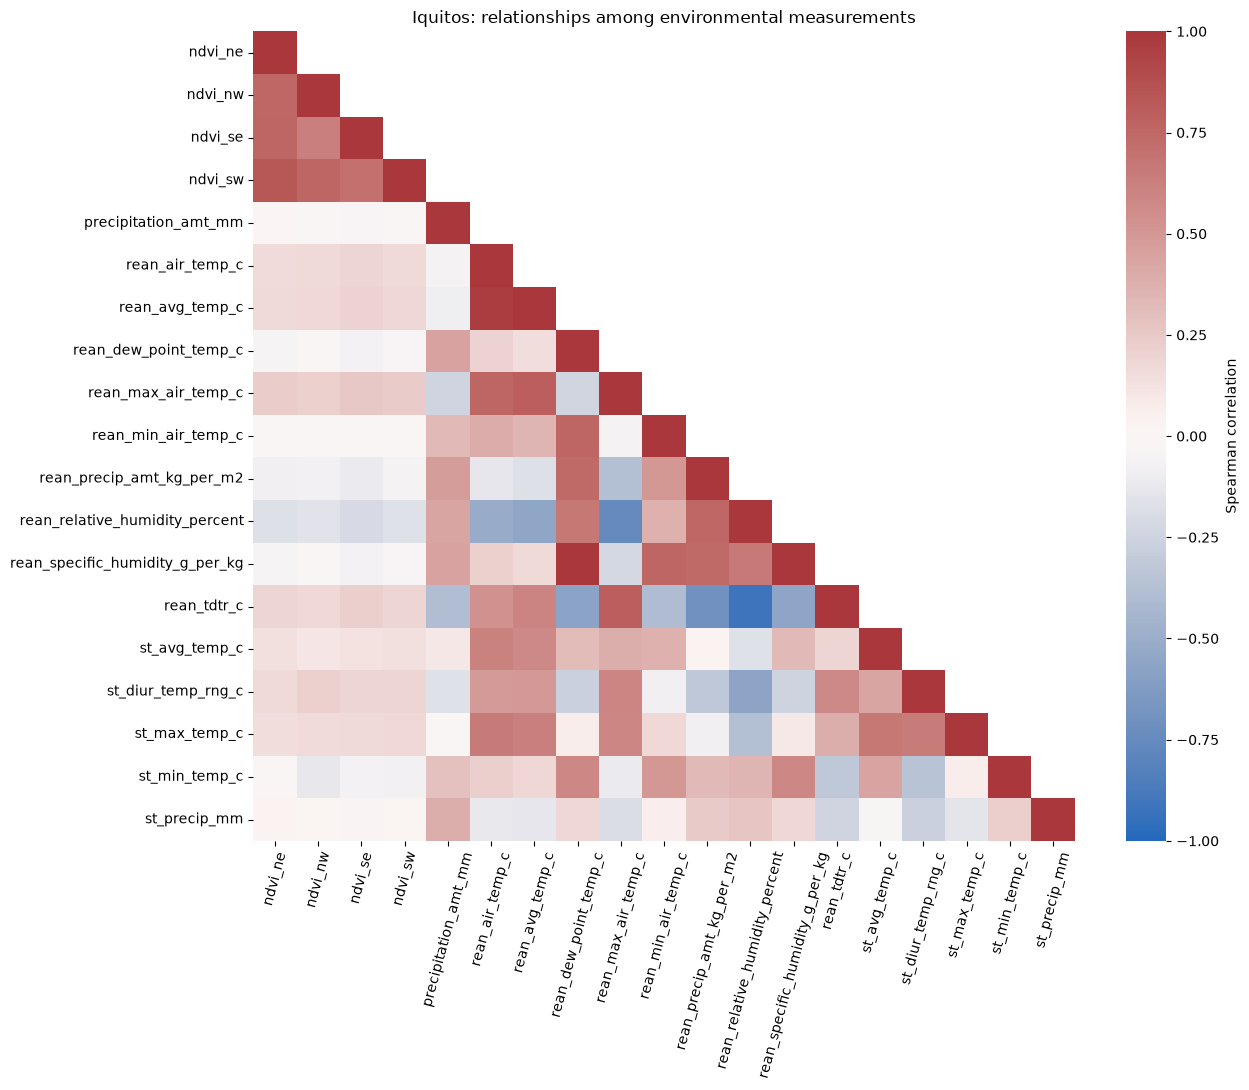

In [15]:
nrows = int(np.ceil(len(plot_features) / 3))
for city in CITIES:
    group = df_train_eda.loc[df_train_eda['city'].eq(city)]
    fig, axes = plt.subplots(nrows, 3, figsize=(16, 2.8 * nrows))
    for ax, feature in zip(axes.flat, plot_features):
        sns.scatterplot(data=group, x=feature, y=TARGET, color=COLORS[city], alpha=.35, s=18, edgecolor=None, ax=ax)
        ax.set_title(feature, fontsize=10)
        ax.set_xlabel('')
    for ax in axes.flat[len(plot_features):]:
        ax.set_visible(False)
    fig.suptitle(f'{CITY_NAMES[city]}: cases vs each feature')
    plt.tight_layout()
    plt.show()

for city in CITIES:
    matrix = df_train_eda.loc[df_train_eda['city'].eq(city), plot_features].corr(method='spearman', min_periods=30)
    labels = [c.replace('reanalysis_', 'rean_').replace('station_', 'st_') for c in matrix.columns]
    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(matrix, mask=np.triu(np.ones(matrix.shape, dtype=bool), k=1), xticklabels=labels, yticklabels=labels,
                cmap='vlag', vmin=-1, vmax=1, center=0, ax=ax, cbar_kws={'label': 'Spearman correlation'})
    ax.set_title(f'{CITY_NAMES[city]}: relationships among environmental measurements')
    ax.tick_params(axis='x', rotation=75)
    plt.tight_layout()
    plt.show()

## 12. Temporal dependence and lagged weather

**Case autocorrelation:** how strongly this week's cases relate to earlier weeks of cases. It matters because in the test period past case counts are unavailable, so any model that uses them needs a recursive forecast.

**Lagged weather:** Spearman correlation between cases at observation *t* and a feature at *t − L*, L = 0…12. Shifts are done within city after sorting. Lags are observation offsets (about weeks). Serial dependence and shared seasonality inflate these numbers, so they suggest experiments; they do not identify a causal delay.

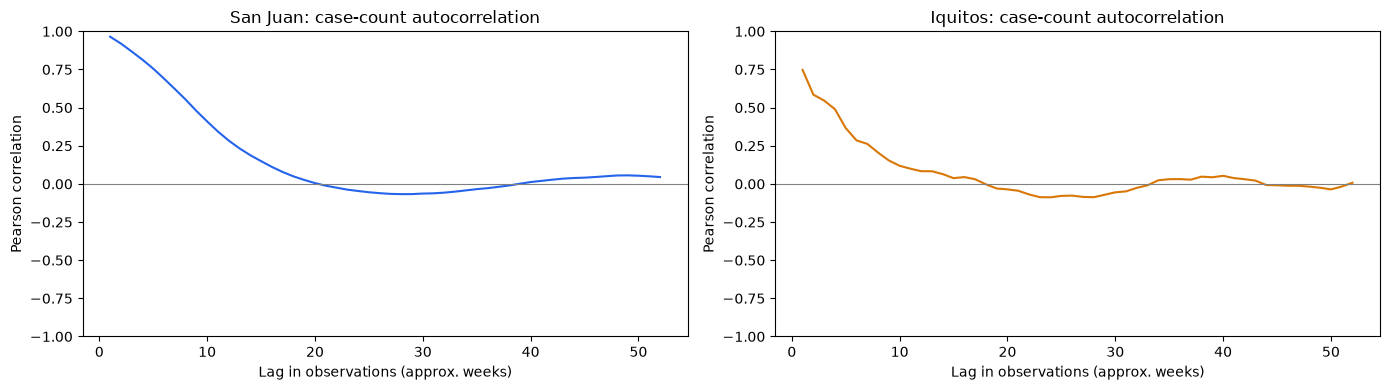

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, city in zip(axes, CITIES):
    cases = df_train.loc[df_train['city'].eq(city)].sort_values('week_start_date')[TARGET]
    lag_numbers = np.arange(1, 53)
    ax.plot(lag_numbers, [cases.autocorr(lag=int(lag)) for lag in lag_numbers], color=COLORS[city])
    ax.axhline(0, color='gray', lw=.8)
    ax.set(title=f'{CITY_NAMES[city]}: case-count autocorrelation', xlabel='Lag in observations (approx. weeks)',
           ylabel='Pearson correlation', ylim=(-1, 1))
plt.tight_layout()
plt.show()

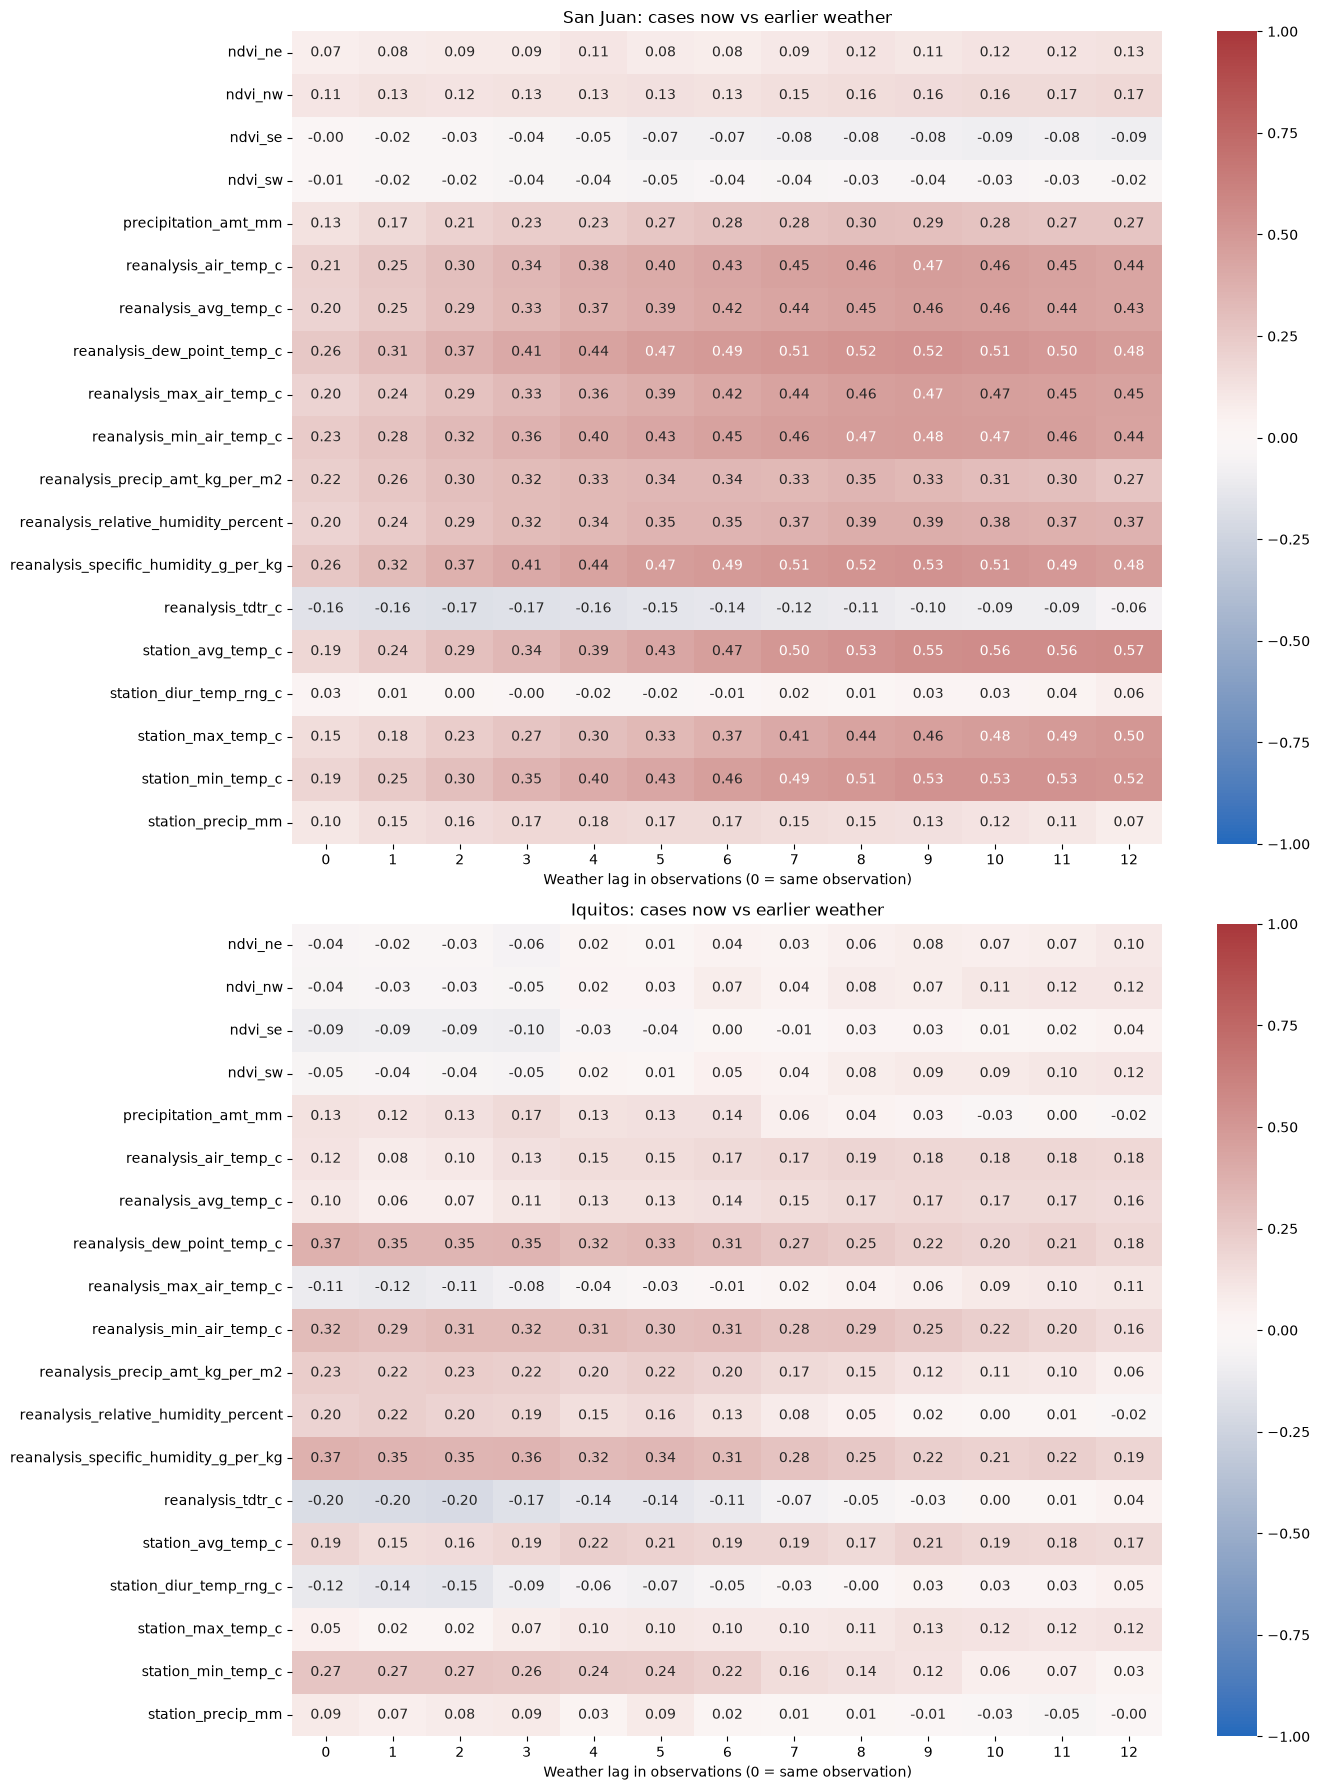

In [17]:
MAX_WEATHER_LAG = 12
lag_records = []
for city in CITIES:
    group = df_train_eda.loc[df_train_eda['city'].eq(city)].sort_values('week_start_date').reset_index(drop=True)
    for feature in plot_features:
        for lag in range(MAX_WEATHER_LAG + 1):
            earlier = group[feature].shift(lag)
            valid = earlier.notna() & group[TARGET].notna()
            corr = earlier[valid].corr(group.loc[valid, TARGET], method='spearman') if valid.sum() >= 30 else np.nan
            lag_records.append({'city': city, 'feature': feature, 'lag': lag, 'spearman': corr, 'n_pairs': int(valid.sum())})
lag_correlations = pd.DataFrame(lag_records)

fig, axes = plt.subplots(2, 1, figsize=(14, 18))
for ax, city in zip(axes, CITIES):
    table = (lag_correlations.loc[lag_correlations['city'].eq(city)]
             .pivot(index='feature', columns='lag', values='spearman').reindex(plot_features))
    sns.heatmap(table, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0, ax=ax)
    ax.set(title=f'{CITY_NAMES[city]}: cases now vs earlier weather',
           xlabel='Weather lag in observations (0 = same observation)', ylabel='')
plt.tight_layout()
plt.show()

# CORE = ['reanalysis_specific_humidity_g_per_kg', 'station_avg_temp_c', 'precip_log1p', 'reanalysis_tdtr_c']

**Observations (§12).** Case autocorrelation is very high at short lags and decays: for `sj` it is 0.96 at lag 1, 0.81 at lag 4, 0.55 at lag 8 and about 0 by half a year; for `iq` it is 0.75, 0.49 and 0.21 respectively. Earlier weather is more informative than same-week weather for `sj` (Spearman about 0.5 for temperature and humidity at lags 8–12, rising towards the edge of the window), but much less so for `iq`. These correlations include shared seasonality.

---
# Part B — Additional analyses

Part A leaves several questions open that matter for model choice: *how* overdispersed are the counts, does the case level shift between years, and do the two cities respond to weather differently?

## 13. Overdispersion of case counts

A Poisson model assumes variance ≈ mean. Count data with outbreaks usually have variance far above the mean (**overdispersion**), which favours a Negative Binomial likelihood or a robust loss.

Two views, both per city:
1. Overall variance-to-mean ratio. The overall variance mixes seasonal and between-year differences in the *level*, so it overstates dispersion at any one moment.
2. Dispersion at the same week of year across years. Comparing the same week removes the seasonal swing; what remains is the year-to-year variation, so this is still an upper bound on what a model with seasonal terms has to absorb.

The Negative Binomial variance is `μ + α·μ²`; `α` below is estimated by moments (overall) and by least squares on the week-of-year points. Larger `α` means heavier overdispersion; `α = 0` is Poisson.

In [18]:
cases_by_city = {c: df_train.loc[df_train['city'].eq(c)].sort_values('week_start_date')[TARGET] for c in CITIES}

# 1. Overall
overall = pd.DataFrame({
    c: {'mean': s.mean(), 'variance': s.var(), 'variance_to_mean': s.var() / s.mean(),
        'alpha_moment_estimate': (s.var() - s.mean()) / s.mean() ** 2}
    for c, s in cases_by_city.items()}).T
display(overall.round(3))

# 2. Same week of year across years
by_week = df_train.groupby(['city', 'weekofyear'])[TARGET].agg(['mean', 'var', 'size'])
by_week = by_week.loc[(by_week['mean'] > 0) & (by_week['size'] >= 5)]
print('Same-week-of-year variance-to-mean ratio (across years):')
display((by_week['var'] / by_week['mean']).groupby('city').describe(percentiles=[.1, .5, .9]).round(2))

,mean,variance,variance_to_mean,alpha_moment_estimate
sj,34.181,2640.045,77.238,2.230
iq,7.565,115.896,15.319,1.893


Same-week-of-year variance-to-mean ratio (across years):


,count,mean,std,min,10%,50%,90%,max
city,,,,,,,,
iq,52.0,9.45,10.72,1.49,2.19,4.86,20.30,61.56
sj,52.0,45.99,41.68,6.73,7.93,26.40,112.47,150.53


Least-squares NB alpha on week-of-year points: {'iq': np.float64(1.69), 'sj': np.float64(1.575)}


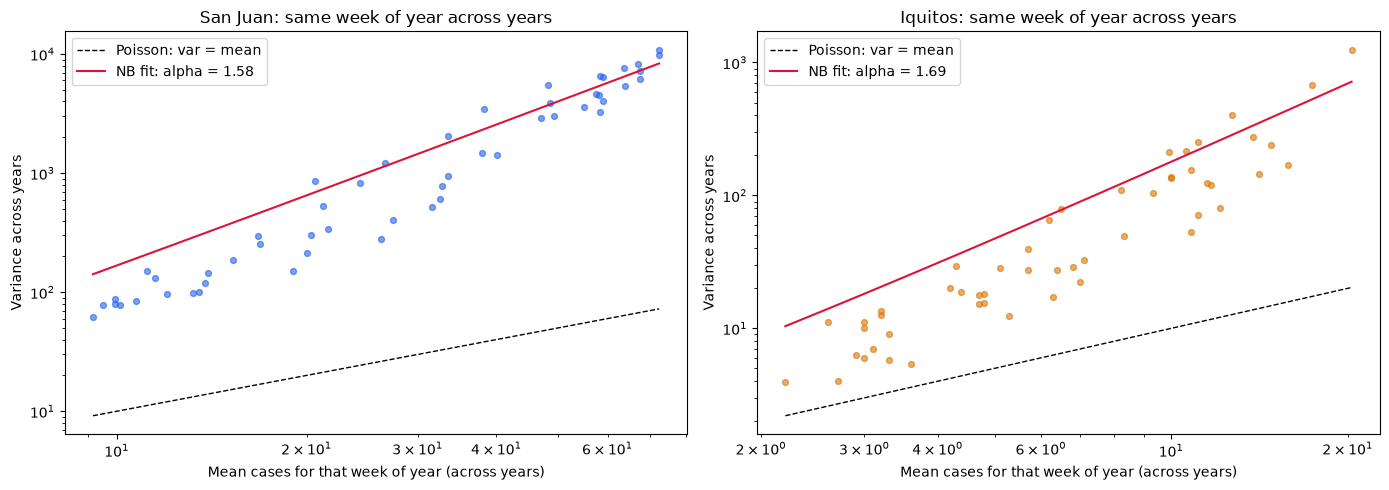

In [19]:
# Same week of year across years: one point per (city, week of year)
week_stats = by_week.reset_index().rename(columns={'var': 'variance'})
alpha_week = {c: ((g['variance'] - g['mean']) * g['mean'] ** 2).sum() / (g['mean'] ** 4).sum()
              for c, g in week_stats.groupby('city')}
print('Least-squares NB alpha on week-of-year points:', {c: round(a, 3) for c, a in alpha_week.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, city in zip(axes, CITIES):
    g = week_stats.loc[week_stats['city'].eq(city)]
    ax.scatter(g['mean'], g['variance'], s=18, alpha=.6, color=COLORS[city])
    grid = np.linspace(g['mean'].min(), g['mean'].max(), 200)
    ax.plot(grid, grid, 'k--', lw=1, label='Poisson: var = mean')
    ax.plot(grid, grid + alpha_week[city] * grid ** 2, color='crimson', lw=1.5,
            label=f'NB fit: alpha = {alpha_week[city]:.2f}')
    ax.set(xscale='log', yscale='log', title=f'{CITY_NAMES[city]}: same week of year across years',
           xlabel='Mean cases for that week of year (across years)', ylabel='Variance across years')
    ax.legend()
plt.tight_layout()
plt.show()

**Observations (§13).** Counts are strongly overdispersed in both cities. Over the whole series the variance-to-mean ratio is 77 (`sj`) and 15 (`iq`), but that mixes in the seasonal swing and the level shifts. Comparing the same week of year across years removes the seasonal swing, and variance is still above the mean in every week of the year: the median ratio is 26 (`sj`) and 4.9 (`iq`), and the fitted NB `α` is about 1.6 and 1.7. The points follow the `μ + α·μ²` shape, curving away from the Poisson line as the mean grows. A Poisson likelihood is a poor fit; Negative Binomial or a robust loss is better matched.

## 14. Year-to-year level shifts

Is the *baseline* of cases stable across years, or does it shift? A shift would make a model fitted on early years mis-calibrated for the test years.

The table and bar chart give the mean, median, maximum and peak week of cases for each year. The first and last year of each city are partial, so compare means, not totals.

weeks  mean_cases  median_cases  max_cases  peak_week
city year                                                       
iq   2000     26         0.2           0.0          1         36
     2001     52         0.3           0.0          4         51
     2002     52        13.5          11.0         38         49
     2003     52         2.2           2.0         10          1
     2004     52        12.3           6.0        116         50
     2005     52         6.0           5.5         16         14
     2006     52         8.4           6.0         39          5
     2007     52         7.0           6.0         28         50
     2008     52        15.4           7.5         63         42
     2009     52         6.2           4.0         35          5
     2010     26         8.6           8.5         19          7
sj   1990     35        24.7          23.0         71         45
     1991     52        53.9          24.0        169         48
     1992     52        45.6          37.5        104          2
     1993     52        22.2          22.0         46         45
     1994     52       125.6          40.5        461         41
     1995     52        25.6          18.0        154         52
     1996     52        16.4          16.0         35         43
     1997     52        28.0          20.5        112         44
     1998     52        88.4          67.0        329         32
     1999     52        31.4          27.5         77          2
     2000     52         9.5           6.0         38         46
     2001     52        28.1          18.5         75         45
     2002     52         8.7           6.0         38          2
     2003     52        18.2          14.5         41         40
     2004     52        11.7          12.0         27         39
     2005     52        34.7          17.0        137         35
     2006     52        10.6          10.0         33         38
     2007     52        37.9          21.0        170         40
     2008     17         6.2           5.0         15          1

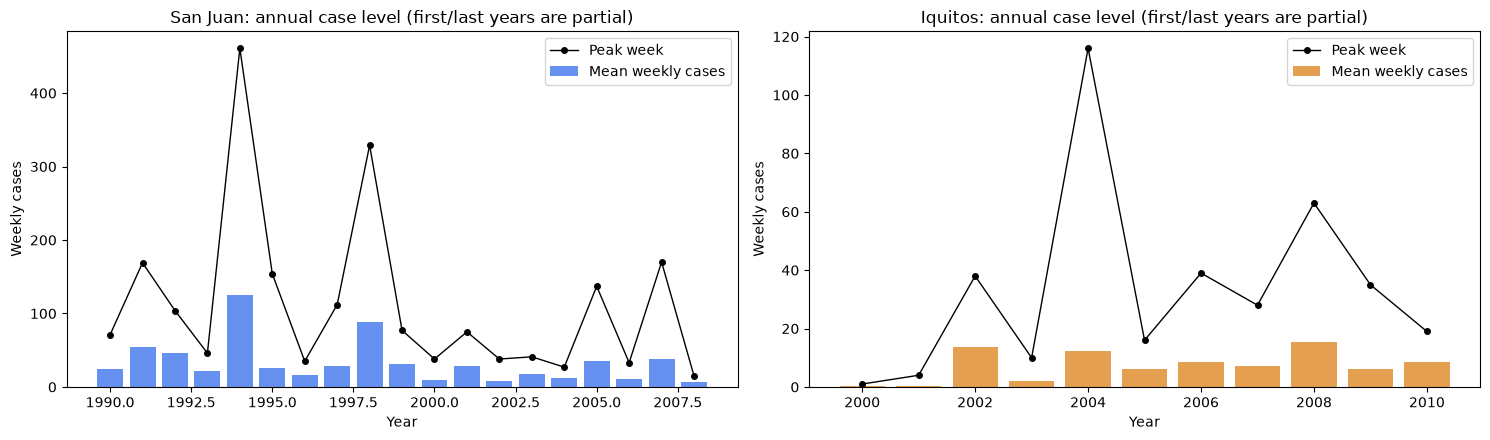

In [20]:
annual = df_train.groupby(['city', 'year']).agg(
    weeks=(TARGET, 'size'), mean_cases=(TARGET, 'mean'), median_cases=(TARGET, 'median'), max_cases=(TARGET, 'max'))
peak = df_train.loc[df_train.groupby(['city', 'year'])[TARGET].idxmax()].set_index(['city', 'year'])['weekofyear']
annual['peak_week'] = peak
display(annual.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, city in zip(axes, CITIES):
    g = annual.loc[city]
    ax.bar(g.index, g['mean_cases'], color=COLORS[city], alpha=.7, label='Mean weekly cases')
    ax.plot(g.index, g['max_cases'], color='black', marker='o', ms=4, lw=1, label='Peak week')
    ax.set(title=f'{CITY_NAMES[city]}: annual case level (first/last years are partial)', xlabel='Year', ylabel='Weekly cases')
    ax.legend()
plt.tight_layout()
plt.show()

**Observations (§14).** The case level is not stable. Across full years, mean weekly cases in `sj` range from 8.7 (2002) to 126 (1994), with a second large year in 1998 (88). `iq` is near zero in 2000–2001 (0.2–0.3 per week), then ranges from 2.2 (2003) to 15.4 (2008). The size of a year cannot be read from the previous year. `sj` peaks fall in weeks 32–52 in most years and in weeks 1–2 in a few, while `iq` peak weeks move around the calendar (weeks 1–14 or 42–51 in full years). A model must cope with level shifts it cannot see in advance, and a `year` trend can only describe a slow drift, not these jumps.

## 15. Do the two cities behave differently?

Evidence for or against sharing one model across cities:
- Within-city weather–case correlations side by side (a sign difference is a strong warning against pooling a linear effect).
- The pooled correlation, to show how pooling mixes city differences into the relationship.
- The lag with the strongest correlation in each city (from Section 12; descriptive only).
- Seasonal profile: timing of the yearly peak, and whether the two seasonal shapes are similar.
- Whether the two cities' outbreaks are synchronous when both are observed (2000–2008).

In [21]:
pooled = df_train_eda[plot_features + [TARGET]].corr(method='spearman', min_periods=30)[TARGET].drop(TARGET)
comparison = pd.DataFrame({'sj': spearman_table['sj'], 'iq': spearman_table['iq'], 'pooled': pooled})
comparison['sj_minus_iq'] = comparison['sj'] - comparison['iq']
comparison['sign_differs'] = np.sign(comparison['sj']) != np.sign(comparison['iq'])
print('Spearman with total_cases: within each city vs pooled')
display(comparison.sort_values('sj_minus_iq', key=abs, ascending=False).round(3))

# Strongest lag per city and feature
valid_lags = lag_correlations.dropna(subset=['spearman'])
best = valid_lags.loc[valid_lags.assign(a=valid_lags['spearman'].abs()).groupby(['city', 'feature'])['a'].idxmax()]
best_table = best.pivot(index='feature', columns='city', values=['lag', 'spearman']).reindex(plot_features)
print('Strongest |Spearman| over lags 0-12, per city:')
display(best_table.round(2))

Spearman with total_cases: within each city vs pooled


,sj,iq,pooled,sj_minus_iq,sign_differs
reanalysis_max_air_temp_c,0.202,-0.106,-0.376,0.308,True
ndvi_nw,0.115,-0.042,-0.350,0.157,True
station_diur_temp_rng_c,0.027,-0.118,-0.426,0.144,True
reanalysis_dew_point_temp_c,0.258,0.368,0.172,-0.110,False
reanalysis_specific_humidity_g_per_kg,0.263,0.372,0.147,-0.109,False
ndvi_ne,0.070,-0.037,-0.404,0.107,True
reanalysis_avg_temp_c,0.201,0.099,0.164,0.102,False
station_max_temp_c,0.154,0.053,-0.249,0.101,False
ndvi_se,-0.000,-0.094,-0.266,0.094,False
reanalysis_air_temp_c,0.207,0.122,0.361,0.086,False


Strongest |Spearman| over lags 0-12, per city:


lag       spearman      
city                                     iq    sj       iq    sj
feature                                                         
ndvi_ne                                12.0  12.0     0.10  0.13
ndvi_nw                                12.0  12.0     0.12  0.17
ndvi_se                                 3.0  12.0    -0.10 -0.09
ndvi_sw                                12.0   5.0     0.12 -0.05
precipitation_amt_mm                    3.0   8.0     0.17  0.30
reanalysis_air_temp_c                   8.0   9.0     0.19  0.47
reanalysis_avg_temp_c                   9.0   9.0     0.17  0.46
reanalysis_dew_point_temp_c             0.0   9.0     0.37  0.52
reanalysis_max_air_temp_c               1.0   9.0    -0.12  0.47
reanalysis_min_air_temp_c               3.0   9.0     0.32  0.48
reanalysis_precip_amt_kg_per_m2         0.0   8.0     0.23  0.35
reanalysis_relative_humidity_percent    1.0   9.0     0.22  0.39
reanalysis_specific_humidity_g_per_kg   0.0   9.0     0.37  0.53
reanalysis_tdtr_c                       2.0   2.0    -0.20 -0.17
station_avg_temp_c                      4.0  12.0     0.22  0.57
station_diur_temp_rng_c                 2.0  12.0    -0.15  0.06
station_max_temp_c                      9.0  12.0     0.13  0.50
station_min_temp_c                      0.0  10.0     0.27  0.53
station_precip_mm                       3.0   4.0     0.09  0.18

Peak week of the smoothed seasonal profile: {'iq': 4, 'sj': 42}
Spearman between the two seasonal profiles: 0.237


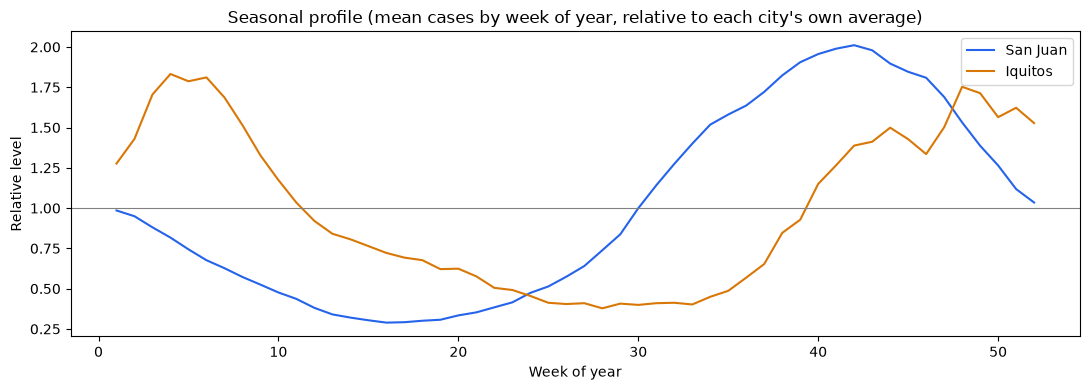

Overlapping weeks with both cities observed: 407
Spearman correlation of weekly cases, sj vs iq: -0.261


In [22]:
# Seasonal profile: week-of-year mean, lightly smoothed (circular, 5 weeks)
profile_mean = df_train.groupby(['city', 'weekofyear'])[TARGET].mean().unstack('city').reindex(range(1, 53))
padded = pd.concat([profile_mean.iloc[-4:], profile_mean, profile_mean.iloc[:4]])
smooth = padded.rolling(5, center=True).mean().iloc[4:-4]
normalised = smooth / smooth.mean()
print('Peak week of the smoothed seasonal profile:', smooth.idxmax().to_dict())
print('Spearman between the two seasonal profiles:', round(smooth['sj'].corr(smooth['iq'], method='spearman'), 3))

fig, ax = plt.subplots(figsize=(11, 4))
for city in CITIES:
    ax.plot(normalised.index, normalised[city], color=COLORS[city], label=CITY_NAMES[city])
ax.axhline(1, color='gray', lw=.8)
ax.set(title='Seasonal profile (mean cases by week of year, relative to each city\'s own average)',
       xlabel='Week of year', ylabel='Relative level')
ax.legend()
plt.tight_layout()
plt.show()

# Are outbreaks synchronous when both cities are observed?
both = (df_train.pivot_table(index=['year', 'weekofyear'], columns='city', values=TARGET).dropna())
print(f'Overlapping weeks with both cities observed: {len(both)}')
print('Spearman correlation of weekly cases, sj vs iq:', round(both['sj'].corr(both['iq'], method='spearman'), 3))

**Observations (§15).** The two cities differ enough that a single shared model is risky. Four features change sign between cities (`reanalysis_max_air_temp_c`, `station_diur_temp_rng_c`, `ndvi_ne`, `ndvi_nw`), and pooled correlations can be misleading: the diurnal range correlates about −0.43 with cases when pooled but about 0 within either city. Humidity, rainfall and minimum temperature have the same sign and similar size in both cities, so sharing those effects is more defensible. The strongest lags differ: mostly 8–12 weeks in `sj`, 0–4 weeks in `iq`. The seasonal peak is around week 42 in `sj` and week 4 in `iq` (correlation between the two seasonal profiles 0.24), and weekly cases are negatively correlated where both cities are observed (Spearman −0.26). The seasonal curve should be city-specific, and any pooled model needs at least a city indicator.

## 16. Summary of findings and modelling implications

**Data quality**
- All integrity checks pass: dates agree with `year`/`weekofyear`, keys are unique, features and labels join one-to-one, test follows train in each city, and the test keys match the submission template.
- `precipitation_amt_mm` and `reanalysis_sat_precip_amt_mm` are identical, so only one is needed (19 distinct environmental columns).
- Missingness is mostly small. The exception is `ndvi_ne` (about 20% missing for `sj` in train, 17% in test). The chronological plot shows scattered short gaps rather than long blocks (§4).

**Target**
- The two cities are very different. `sj` averages 34 cases per week (maximum 461); `iq` averages 7.6 (maximum 116), and 18% of `iq` weeks have zero cases.
- Counts are strongly **overdispersed** (§13). The overall variance-to-mean ratio is 77 (`sj`) and 15 (`iq`). Comparing the same week of year across years, which removes the seasonal swing, the median ratio is still 26 (`sj`) and 4.9 (`iq`), and variance exceeds the mean in every week of the year (NB `α` about 1.6 and 1.7). A Poisson likelihood is a poor fit; Negative Binomial or a robust (MAE/quantile) loss is better matched.
- A few outbreaks dominate the scale (`sj` 1994 and 1998, `iq` 2004). The baseline level is **not stable** across years (§14): across full years, mean weekly cases range from about 9 to 126 for `sj`, and `iq` is near zero in 2000–2001. A model must cope with level shifts it cannot see in advance.
- Case counts are strongly autocorrelated (lag-1 correlation 0.96 for `sj`, 0.75 for `iq`; still 0.55 and 0.21 at 8 weeks). Using past cases is powerful in-sample, but the test period has no case history, so it requires recursive forecasting, where errors compound.

**Seasonality and the two cities**
- Both cities have an annual cycle, but at different times: the smoothed seasonal peak is around week 42 for `sj` and around week 4 for `iq`. Weekly cases in the two cities are *negatively* correlated where both are observed (Spearman −0.26, §15). `iq` peak timing is also much less regular year to year.
- Weather distributions differ between cities (for example `ndvi_ne` mean 0.26 for `iq` vs 0.06 for `sj`).
- Pooled weather–case correlations are misleading. For example, the diurnal temperature range correlates −0.43 with cases when pooled, but about 0 within either city, because it separates the cities. Four features change sign between cities (`reanalysis_max_air_temp_c`, `station_diur_temp_rng_c`, `ndvi_ne`, `ndvi_nw`). Within-city analysis is essential, and any pooled model needs a city indicator and ideally city-specific effects.

**Weather signal**
- Same-week weather correlations are weak (|Spearman| at most about 0.26 for `sj` and 0.37 for `iq`). The strongest are specific humidity, dew point and minimum temperature. NDVI carries almost no linear signal.
- Earlier weather correlates more strongly for `sj` (about 0.5 at lags 8–12 for temperature and humidity), which supports lagged-weather features. For `sj` many best lags sit at the edge of the window tested (12), so longer lags are worth testing. For `iq`, lagging adds little. These lagged correlations are inflated by shared seasonality and are suggestions, not proof.
- Many reanalysis and station variables measure overlapping things (strongly correlated with one another), so feature selection or regularisation is sensible.

**Implications for modelling**
1. Evaluate with chronological, forecast-style validation, including a long horizon (the test is 3–5 years), not random folds.
2. Treat the cities separately, or pool only with city-aware terms. Compare both.
3. Use a count-appropriate or robust objective (Negative Binomial / Poisson with overdispersion allowance / MAE loss).
4. Include seasonal terms (sine/cosine of day of year), and test lagged weather (including lags beyond 12 for `sj`).
5. Be cautious with `year` (it extrapolates beyond the training range in the test period) and with case-history features that need recursive prediction.
6. Impute missing values using only earlier weeks; the gaps are short.
7. Keep outbreak weeks; they are real events and the main source of error.